# Evolutionary search for new coding algorithms (iteration 7, claim N)

**Question.** Can an evolutionary program search make an 8B model write correct **out-of-catalogue** algorithms far
more often per call than the best single-sample prompting? An out-of-catalogue program is one whose core idea is not
one of the task's standard textbook solutions.

**The original experiment.**

* **Mutator:** Qwen3-8B (bf16, thinking off, vLLM, temperature 1.0), on one RTX A4500.
* **Search (arm S):** FunSearch-style islands over a MAP-Elites archive. Each round runs 4 islands × 3 prompts × 4
  children, and every prompt shows 2 parent programs drawn by a Boltzmann choice over archive cells.
* **Evaluator:** an AST pre-screen, then a sandboxed subprocess with 3 stages: 8 quick cases, the hidden suite, and
  10 seeded max-size stress inputs.
* **Novelty critic:** token 4-gram Jaccard similarity *s* to 18,237 known code solutions plus the catalogue
  references. Novelty is ν = 1 − s.
* **Tasks:** T2 shortest path, T03 k-th smallest, A3 trapping rain water.
* **Comparison arms:**
  * NE: the same prompt with frozen seed parents (no evolution);
  * I0: the instruction alone;
  * EAP and BINT: the two best prompting knobs of iteration 5;
  * B0: a neutral prompt;
  * L: qwen3-235b as the mutator, 500 calls.

**Pre-registered prediction.** S ≥ 10× K on ≥ 2 tasks, where K is the better of EAP and BINT on each task. The count is
distinct programs that pass the out-of-catalogue (OOC) screen ("level a").

**Result: NOT MET.**

| Task | Level a: S vs K | R̂ | LB95 |
|---|---|---|---|
| T2 | 46/1500 vs 6/750 | 3.83 | 1.83 |
| T03 | 412/2500 vs 31/1250 | 6.65 | 4.86 |
| A3 | 31/1000 vs 17/500 | 0.91 | 0.54 |

Only T03 produced level-b programs, i.e. programs adjudicated as known-outside-catalogue: S had 78 and EAP had 0. Every
out-of-catalogue program is a **known** technique: value-range binary search, Fenwick-tree or treap order statistics,
bucket select, or partial selection sort. There were **0 novel algorithms**.

**What this notebook runs.** `method.py` is a stage CLI:
`inputs → corpus → tests → commit0 → calib → commit1 → base → run → L → label → adjudicate → analyse → outputs`.

Two kinds of stage cannot run in a 10-minute CPU notebook: the GPU stages (Qwen3-8B generation, about 1 GPU-hour) and
the OpenRouter stages (LLM judges, arm L). Their **recorded outputs are replayed** from `mini_demo_data.json`, which
holds 100 correct T03 programs from every arm, including one complete 12-program S lineage.

Everything downstream of generation runs for real, with the original code of `method.py` and `src/`:

1. the pre-registration record and the commit #0 / #1 hash chain;
2. the sandboxed three-stage evaluator, re-run on every program;
3. the novelty critic, run over a corpus subset that contains every demo program's true nearest neighbour, so *s* matches
   the full run;
4. commit #1: the s\* calibration and N per arm;
5. a replay of the S arm through the MAP-Elites islands;
6. the OOC screen, distinct programs and idea clusters;
7. the pre-registered statistics and verdict, on the full run's per-arm counts.

Cells marked **"Notebook change"** are the only places where the original code was adapted.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, scipy, matplotlib, pandas — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- method.py's import block (as in the original) ---
import argparse
import json
import sys
import time
from pathlib import Path

from loguru import logger

# --- imports of the src/ modules this notebook inlines (common, inputs, sandbox, critic, labels, search, prompts,
#     analysis, run, finalize, adjudicate, figures) and of tests/test_units.py ---
import ast
import builtins
import hashlib
import importlib.util
import io
import itertools
import keyword
import math
import os
import random
import re
import resource
import shutil
import statistics
import threading
import tokenize
import zlib
from collections import Counter, defaultdict
from concurrent.futures import Future, ThreadPoolExecutor
from datetime import datetime, timezone
from functools import lru_cache
from typing import Any, Iterable

import numpy as np
from scipy import sparse, stats

# --- notebook additions: tables and figures ---
import textwrap

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-37/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
print(f"{len(EXAMPLES)} programs from dataset '{data['datasets'][0]['dataset']}', task {data['metadata']['demo_task']}")
print("per arm:", dict(Counter(e["metadata_arm"] for e in EXAMPLES)))
print("final classes:", dict(Counter(e["metadata_final_class"] or "in catalogue (screen 'in')" for e in EXAMPLES)))
print("corpus subset:", len(data["metadata"]["corpus_subset"]), "known solutions | calibration rows:",
      len(data["metadata"]["calibration_rows"]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 programs from dataset 'search_programs', task T03
per arm: {'S': 46, 'NE': 10, 'I0': 10, 'EAP': 10, 'BINT': 8, 'B0': 4, 'L': 12}
final classes: {"in catalogue (screen 'in')": 56, 'CATALOGUE VARIANT': 23, 'KNOWN OUTSIDE CATALOGUE': 21}
corpus subset: 258 known solutions | calibration rows: 510


## Configuration

All tunable parameters are set here. The demo values keep the notebook to a few minutes on a Colab CPU; the original
run's values are in the comments. Programs are taken round-robin across arms, so even a small `N_EVAL_PROGRAMS` covers
several arms.

In [5]:
# ---- Tunable parameters (demo values; the original run's values are in the comments) ----
DEMO_TASK = data["metadata"]["demo_task"]  # "T03" (k-th smallest): the only task where level-b programs appeared
N_EVAL_PROGRAMS = 100      # demo programs replayed through evaluator + critic + archive (the demo file holds 100;
                           # original: every generated child, 13,100 decisive calls + 500 L calls)
EVAL_WORKERS = 2           # evaluator threads (original src/run.py: EVAL_WORKERS = 8)
GPU_HOURS_AVAILABLE = 2.0  # GPU budget fed to commit #1's ladder (original: `--stage commit1 --gpu-hours 2.0`)
PLACEBO_REPS = 200         # arm-shuffle placebo repetitions (original: 200)
BOOTSTRAP_REPS = 2000      # island-cluster bootstrap repetitions (original: 2000)

## Shared helpers (`src/common.py`)

This module holds paths, JSON I/O, seeded hashing (`stable_seed`) and the **commitments hash chain**. Every
pre-registration commit appends `sha256(file)`, chained to the previous line, so a later edit to a committed file is
detectable (`verify_chain`). The notebook works in a fresh local folder, `evolve_demo_workspace/`.

In [6]:
# ---- src/common.py (inlined; logic unchanged except where marked) ----
# Notebook change: a fresh local working folder instead of the artifact directory
ROOT = Path("evolve_demo_workspace").resolve()
shutil.rmtree(ROOT, ignore_errors=True)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
VENDOR = INPUTS / "vendor"
DATA = ROOT / "data"
RAW = DATA / "raw"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
PRED = ROOT / "predictions"
AUDIT = ROOT / "audit"
LOGS = ROOT / "logs"
COMMITS = ROOT / "commitments.log"
for _d in (INPUTS, VENDOR, DATA, RAW, RESULTS, FIGS, PRED, AUDIT, LOGS):
    _d.mkdir(parents=True, exist_ok=True)
SRC.mkdir(parents=True, exist_ok=True)   # notebook change: the evaluator's child script is written here

# <runs>/<run>/3_invention_loop/iter_7/gen_art/<this artifact>
RUNS_DIR = ROOT   # notebook change: no run layout around the demo folder (was AII_RUNS_DIR or ROOT.parents[4])
DEP_REL = "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_dataset_1"  # declared dependency art_j3Rm_lr2nzR6
_DEP_SIBLING = ROOT.parent / "art_j3Rm_lr2nzR6"   # the published repository holds the dependency as a sibling folder
DEP_DIR = Path(os.environ.get("ART_J3RM_DIR") or (str(_DEP_SIBLING) if _DEP_SIBLING.exists() else str(RUNS_DIR / DEP_REL)))

# read-only sources of the non-declared items (vendored once at STEP 1; paths relative to RUNS_DIR)
VENDOR_SOURCES: dict[str, str] = {
    "bench": "run_0oWBKrKEGsmU/3_invention_loop/iter_6/gen_art/gen_art_experiment_29/vendor/exp22/inputs/exp11/bench",
    "exp8_suite": "run_0oWBKrKEGsmU/3_invention_loop/iter_6/gen_art/gen_art_experiment_30/inputs/exp8/suite",
    "exp30_src": "run_0oWBKrKEGsmU/3_invention_loop/iter_6/gen_art/gen_art_experiment_30/src",
    "newbench": "run_aRfWvcSWjssb/3_invention_loop/iter_5/gen_art/gen_art_experiment_25/newbench",
    "exp27": "run_aRfWvcSWjssb/3_invention_loop/iter_5/gen_art/gen_art_experiment_27",
    "exp29_results": "run_0oWBKrKEGsmU/3_invention_loop/iter_6/gen_art/gen_art_experiment_29/results",
    "B7": "run_aRfWvcSWjssb/3_invention_loop/iter_5/gen_art/gen_art_experiment_26/units/B7",
}

# ------------------------------------------------------------------------------------------------ model / decoding
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REV = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"
TEMPERATURE = 1.0
TOP_P = 1.0
MAX_TOKENS = {"T2": 1536, "T03": 1024, "A3": 1024}
VLLM_SEED = 7101
TASKS = ("T2", "T03", "A3")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
CAP_USD = {"label_disputes": 0.5, "adjudication": 1.8, "L": 1.0, "reserve": 0.2}
CAP_TOTAL_USD = 3.5

ARMS_DECISIVE = ("S", "NE", "I0", "EAP", "BINT", "B0")


# ------------------------------------------------------------------------------------------------ logging
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def trunc(s: Any, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n}]"


# ------------------------------------------------------------------------------------------------ io
def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping a corrupt line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def stable_seed(*parts: Any) -> int:
    """sha256(task|arm|index) mod 2^31: the per-request vLLM seed and every external RNG seed."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 31)


def rel(p: Path) -> str:
    """Workspace-relative POSIX path (never an absolute server path in published files)."""
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        try:
            return "<runs>/" + Path(p).resolve().relative_to(RUNS_DIR.resolve()).as_posix()
        except ValueError:
            return Path(p).name


# ------------------------------------------------------------------------------------------------ hardware
def detect_cpus() -> int:
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return math.ceil(int(parts[0]) / int(parts[1]))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return math.ceil(q / p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def set_ram_limit(gb: float) -> None:
    """Hard address-space cap so a runaway allocation raises MemoryError instead of an OOM kill."""
    b = int(gb * 1024 ** 3)
    resource.setrlimit(resource.RLIMIT_AS, (b, b))


# ------------------------------------------------------------------------------------------------ commitments
def commit(files: list[Path], tag: str, note: str = "") -> str:
    """Hash chain: each line = sha256(file) + sha256(previous line) + UTC (+ tag, file). Returns the last line hash."""
    COMMITS.touch(exist_ok=True)
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()]
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    new = []
    for f in files:
        rec = {"tag": tag, "file": rel(f), "sha256": sha256_file(f), "prev": prev, "utc": utc_now(), "note": note}
        line = json.dumps(rec, sort_keys=True)
        new.append(line)
        prev = sha256_text(line)
    with COMMITS.open("a") as fh:
        for ln in new:
            fh.write(ln + "\n")
    logger.info(f"commit {tag}: {len(files)} file(s), chain head {prev[:12]}")
    return prev


def verify_chain() -> dict[str, Any]:
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()] if COMMITS.exists() else []
    prev = "0" * 64
    ok = True
    bad = []
    for i, ln in enumerate(lines):
        rec = json.loads(ln)
        if rec["prev"] != prev:
            ok = False
            bad.append(i)
        prev = sha256_text(ln)
        f = ROOT / rec["file"]
        if f.exists() and sha256_file(f) != rec["sha256"]:
            # a committed file may only change through a NEW commit line (amendment); the latest line must match
            later = [json.loads(x) for x in lines[i + 1:] if json.loads(x)["file"] == rec["file"]]
            if not later:
                ok = False
                bad.append(i)
    return {"n_lines": len(lines), "ok": ok, "bad_lines": bad, "head": prev}


setup_logging("method_demo")   # method.py main(): setup_logging(f"method_{args.stage}")

## Pre-registration (`method.py`)

These constants were frozen in commit #0, before any GPU sample:

* the hypothesis, the prediction and the verdict rule;
* the budget ladder (N calls per arm);
* the definitions of *correct*, *OOC_screen*, *distinct* and *idea cluster*;
* the tests, the judge models and the judge prompt;
* the 10-control gate plan.

In [7]:
# ---- method.py: pre-registered constants (verbatim) ----
HYPOTHESIS = (
    "Claim N (iteration 7, secondary family): a FunSearch / MAP-Elites program search with Qwen3-8B (bf16, thinking "
    "off, vLLM, T 1.0) as the mutator, hidden tests plus fresh randomised stress tests as the evaluator, and a novelty "
    "critic built against the 18,237 known solutions of art_j3Rm_lr2nzR6 produces correct out-of-catalogue programs "
    "at a much higher rate per call than the best single-sample text knobs of iteration 5, on memorised "
    "LeetCode-style tasks with one 8B mutator.")
PREDICTION = ("S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact "
              "conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen "
              "programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both.")
LADDER = {
    "level0": {"T2": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200},
               "T03": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200}},
    "level1": {"A3": {"S": 1000, "EAP": 500, "BINT": 500, "NE": 300, "I0": 300, "B0": 100}},
    "level2": "raise S on T03 then T2 in +1000 steps up to 4000 while time allows; K arms >= S/2",
    "level3": "reachability (prompt_logprobs teacher forcing) - optional",
    "level4": "large mutator arm L on T03 via OpenRouter, 500 children, <= USD 1.0 - optional, concurrent",
    "level5": "plan noise - first dropped",
    "floors": {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100},
    "drop_order": ["plan_noise", "L (only if OpenRouter binds)", "reachability", "A3", "I0->300,B0->100",
                   "K arms->500", "S->1500->1000 on T2/T03"],
}
DEFINITIONS = {
    "call": "one generated child program (one completion); EAP/BINT count only code-writing calls, their stage-1 GPU "
            "time is charged to their GPU-seconds",
    "correct": "valid (AST pre-screen) AND stage 1 (8 quick cases) AND stage 2 (full hidden suite) AND stage 3 (10 "
               "seeded max-size stress inputs vs the fastest reference)",
    "OOC_screen": "correct AND (final label == 'other' OR nearest-known Jaccard s < s*_task), s*_task = 5th "
                  "percentile of nearest-known similarities of correct forced catalogue programs (label == Y) and "
                  "the references",
    "distinct": "within an arm in call order: identical normalised-token hash merges, then Jaccard >= 0.9 to an earlier "
                "program collapses into it",
    "idea_cluster": "pooled over arms, within each cell (runtime label, DS-signature): single-linkage components at "
                    "Jaccard >= 0.5; after adjudication clusters whose judges named the same algorithm merge",
    "level_a": "distinct OOC_screen programs", "level_b": "distinct adjudicated KNOWN OUTSIDE CATALOGUE + NOVEL",
    "cell": "(runtime label, DS-signature = first 3 of heap, deque_or_queue, sort, bisect, recursion, dict_or_counter, "
            "set, matrix_2d, stack_list, bitops, random, custom_class)",
    "novelty": "nu = 1 - s, s = max token-4-gram Jaccard to corpus + catalogue references (self-match of a seed excluded)",
}
TESTS = {
    "primary": "exact conditional binomial test of two Poisson rates; LB95 from the one-sided Clopper-Pearson bound; "
               "two-sided 95% CI; Holm across tasks",
    "verdict": "STRONG LB95>=10; MET R_hat>=10 & LB95>1; UNRESOLVED R_hat>=10 & LB95<=1; NOT MET R_hat<10; "
               "NOT ESTIMABLE X_S=X_K=0; overall MET if >=2 tasks MET/STRONG",
    "secondary": ["S vs NE", "S vs I0", "NE vs I0", "I0 vs K", "K vs B0", "L vs S (first 500 calls, T03)"],
    "matched_effort": "rarefaction/Chao-1 extrapolation of idea-cluster richness of i.i.d. arms to N_S (trusted to 2x N)",
    "robustness": "island-cluster bootstrap (2,000 reps) of S's rate; arm-shuffle placebo; seeds-as-children check",
    "zero": "rule of three 3/n",
}
JUDGES = {"pair": ["mistralai/mistral-medium-3.1", "moonshotai/kimi-k2-0905"],
          "replacements": ["google/gemini-2.5-flash", "deepseek/deepseek-chat-v3.1", "openai/gpt-4.1-mini"],
          "third": "deepseek/deepseek-chat-v3.1", "temperature": 0, "gate": ">= 9 of 10 controls",
          "label_dispute_judge": "google/gemini-2.5-flash-lite",
          "L_mutator": "qwen/qwen3-235b-a22b-2507", "L_fallback": "qwen/qwen3-coder"}
JUDGE_PROMPT = (
    "You are an expert in algorithms. Decide whether the program below implements a NEW algorithm for a known task.\n\n"
    "TASK\n{spec}\n\nCATALOGUE (the standard known algorithms for this task)\n{catalogue}\n\n"
    "PROGRAM UNDER REVIEW (comments and docstrings removed)\n```python\n{code}\n```\n\n"
    "NEAREST KNOWN SOLUTIONS from a corpus of 18,237 published code solutions (for comparison)\n{nearest}\n\n"
    "SANDBOXED STRESS RESULTS of the program (inputs at three sizes; runtime ratio to the fastest catalogue "
    "reference; log-log slope of runtime against size)\n{stress}\n\n"
    "Classify the program's core algorithm into exactly one class:\n"
    "- NOVEL ALGORITHM: a correct general algorithm whose core mechanism is not in the catalogue and that you cannot "
    "identify as any known published algorithm or textbook technique.\n"
    "- KNOWN OUTSIDE CATALOGUE: a correct general algorithm that is a known, nameable algorithm or textbook technique "
    "not in the catalogue (name it).\n"
    "- CATALOGUE VARIANT: an implementation, restyling or minor modification of a catalogue algorithm (name which).\n"
    "- DEGENERATE: hard-coded or special-cased answers, wrong in general, or brute force that passes only because "
    "the tests are small.\n\n"
    "Answer with JSON only: {{\"class\": \"NOVEL ALGORITHM|KNOWN OUTSIDE CATALOGUE|CATALOGUE VARIANT|DEGENERATE\", "
    "\"named_algorithm\": \"...\", \"core_idea\": \"<one sentence>\", \"confidence\": <0 to 1>, "
    "\"rationale\": \"<at most two sentences>\"}}")
CONTROL_SET_PLAN = [
    "T03 quickselect (Lomuto partition, renamed identifiers) -> CATALOGUE VARIANT",
    "T03 Floyd-Rivest selection -> KNOWN OUTSIDE CATALOGUE",
    "T03 binary search over the value range counting elements <= mid -> KNOWN OUTSIDE CATALOGUE",
    "T03 answer lookup table failing stress -> DEGENERATE",
    "T2 D'Esopo-Pape deque shortest paths -> KNOWN OUTSIDE CATALOGUE",
    "T2 Dijkstra with a hand-written binary-heap class -> CATALOGUE VARIANT",
    "T2 exhaustive simple-path enumeration passing only tiny graphs -> DEGENERATE",
    "A3 sparse-table range-maximum solution -> KNOWN OUTSIDE CATALOGUE",
    "A3 monotonic stack with renamed identifiers -> CATALOGUE VARIANT",
    "A3 decreasing-height processing keeping leftmost/rightmost index -> KNOWN OUTSIDE CATALOGUE",
]

print(HYPOTHESIS, "\n")
print("PREDICTION:", PREDICTION, "\n")
print("VERDICT RULE:", TESTS["verdict"], "\n")
print("Budget ladder, calls per arm (levels 0 and 1):")
print(pd.DataFrame({**LADDER["level0"], **LADDER["level1"]}).T.rename_axis("task"))

Claim N (iteration 7, secondary family): a FunSearch / MAP-Elites program search with Qwen3-8B (bf16, thinking off, vLLM, T 1.0) as the mutator, hidden tests plus fresh randomised stress tests as the evaluator, and a novelty critic built against the 18,237 known solutions of art_j3Rm_lr2nzR6 produces correct out-of-catalogue programs at a much higher rate per call than the best single-sample text knobs of iteration 5, on memorised LeetCode-style tasks with one 8B mutator. 

PREDICTION: S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both. 

VERDICT RULE: STRONG LB95>=10; MET R_hat>=10 & LB95>1; UNRESOLVED R_hat>=10 & LB95<=1; NOT MET R_hat<10; NOT ESTIMABLE X_S=X_K=0; overall MET if >=2 tasks MET/STRONG 

Budget ladder, calls per arm (levels 0 and 

### The stage CLI (`main()`)

The original runs each stage with `uv run method.py --stage <name>`. The dispatcher is defined here for reference but
is **not called**. Each stage runs in the cells below: CPU stages for real, GPU and OpenRouter stages replayed from
their recorded outputs.

In [8]:
# ---- method.py main(): defined for reference only, NOT called in the notebook ----
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--gpu-hours", type=float, default=2.3)
    ap.add_argument("--deadline-min", type=float, default=170.0, help="minutes from now when the GPU run must stop")
    ap.add_argument("--n-l", type=int, default=500)
    ap.add_argument("--tasks", type=str, default="", help="comma list of tasks for --stage adjudicate")
    ap.add_argument("--plan", type=str, default="predictions/commit1.json", help="committed plan (N per arm) to run")
    args = ap.parse_args()
    setup_logging(f"method_{args.stage}")
    if args.stage not in ("calib", "base", "run"):
        set_ram_limit(48.0)   # CPU stages only: RLIMIT_AS breaks CUDA's virtual reservations
    t0 = time.time()
    if args.stage == "inputs":
        from inputs import build_task, vendor_all
        vendor_all()
        for t in TASKS:
            build_task(t, force=True)
    elif args.stage == "corpus":
        from critic import build_corpus
        from inputs import load_task
        build_corpus({t: load_task(t) for t in TASKS}, force=True)
    elif args.stage == "tests":
        import subprocess
        r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], cwd=str(Path(__file__).parent))
        sys.exit(r.returncode)
    elif args.stage == "commit0":
        stage_commit0()
    elif args.stage == "calib":
        from run import stage_calib
        stage_calib()
    elif args.stage == "commit1":
        stage_commit1(args.gpu_hours)
    elif args.stage == "base":
        from run import stage_base
        plan = read_json(PRED / "commit1.json")
        amend = read_json(PRED / "amendment1.json") if (PRED / "amendment1.json").exists() else {}
        want = amend.get("bint_intents_generated", {})
        stage_base({t: max(plan["N"][t].get("BINT", 0), int(want.get(t, 0))) for t in plan["N"]})
    elif args.stage == "run":
        from run import stage_run
        plan = read_json(Path(__file__).resolve().parent / args.plan)
        stage_run(plan, deadline_epoch=time.time() + 60 * args.deadline_min)
    elif args.stage == "L":
        from arm_l import stage_l
        stage_l(args.n_l)
    elif args.stage == "label":
        from finalize import stage_label
        stage_label()
    elif args.stage == "adjudicate":
        from adjudicate import stage_adjudicate
        stage_adjudicate([t for t in args.tasks.split(",") if t] or None)
    elif args.stage == "classes":
        from adjudicate import finalize_classes
        finalize_classes()
    elif args.stage == "analyse":
        from finalize import stage_analyse
        stage_analyse()
    elif args.stage == "outputs":
        from finalize import stage_outputs
        stage_outputs()
    else:
        raise SystemExit(f"unknown stage {args.stage}")
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")
    write_json(RESULTS / f"stage_{args.stage}_done.json", {"utc": utc_now(), "seconds": round(time.time() - t0, 1)})
    _ = json

## STEP 1: Task objects (`src/inputs.py`)

Each task is a frozen benchmark from an earlier iteration. It has a spec, a catalogue of the known algorithms (one
*mode* per standard solution), verified reference implementations, and the evaluator's stages.

STEP 1 assembled these objects from the vendored benchmarks; the demo file ships them pre-built. Only T03 carries its
test stages: 8 quick, 52 hidden and 10 seeded stress cases.

In [9]:
# ---- src/inputs.py: task loading (verbatim) ----
MANIFEST = INPUTS / "vendor_manifest.json"
TASK_DIR = INPUTS / "tasks"
DEFAULT_MODE = {"T2": "dijkstra", "T03": "full_sort", "A3": "prefix_suffix_max"}
GENERIC_FORCED = ["Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
                  "Your solution should use {j}.", "Write an implementation based on {j}.",
                  "Solve the task below using {j}.", "Your solution must implement {j}.",
                  "Write code that implements {j}.", "Base your solution on {j}.", "Apply {j} to solve this task."]
STRESS_SEED = {"T2": 770002, "T03": 770003, "A3": 770043}
N_STRESS = 10


def load_task(task: str) -> dict[str, Any]:
    return read_json(TASK_DIR / f"{task}.json")


def cases_for_display(task_obj: dict[str, Any]) -> dict[str, Any]:
    return {"n_quick": len(task_obj["stages"]["quick"]), "n_rest": len(task_obj["stages"]["rest"]),
            "n_stress": len(task_obj["stages"]["stress"])}


# Notebook change: `vendor_all()` + `build_task(t)` (STEP 1) built these objects from the vendored benches; the demo
# file ships them pre-built (T03 with its stages; T2 and A3 without stages, commit #1 only needs their references).
for t, o in data["metadata"]["tasks"].items():
    write_json(TASK_DIR / f"{t}.json", o)
objs = {t: load_task(t) for t in TASKS}
obj = objs[DEMO_TASK]
print(obj["spec_text"], "\n")
for c in obj["catalogue"]:
    print(f"  - {c['mode']:18s} {c['display_name']}: {c['mechanism'][:90]}")
print("\nstages:", cases_for_display(obj), "| default mode:", obj["default"], "| fastest reference:", obj["fastest_ref"])

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation. 

  - full_sort          a full sort: sort the whole list (sorted/list.sort or a hand-written full sort) and index position k-1
  - size_k_heap        a size-k heap: keep a heap bounded by k elements while scanning (or heapq.nsmallest/nlargest) and read it
  - heapify_pop        heapify-and-pop: heapify all n values into one heap, then pop k times
  - quickselect        qu

## The evaluator (`src/sandbox.py` + `src/sandbox_runner.py`)

A program is **correct** only if it passes four checks in order:

1. the AST pre-screen, which rejects banned imports and calls, and literals over 64 elements (possible lookup tables);
2. 8 quick cases;
3. the full hidden suite;
4. 10 seeded maximum-size stress inputs, checked against the fastest reference.

Programs run in a fresh `python3.12 -I -S` subprocess, with address-space, CPU-time and file-descriptor limits and a
per-case alarm. The child script is written to disk exactly as in the original (`%%writefile`).

In [10]:
%%writefile evolve_demo_workspace/src/sandbox_runner.py
"""Child side of the evaluator sandbox (stdlib only; run as `python3.12 -I -S sandbox_runner.py`, job JSON on stdin).

Limits are applied here before the candidate is executed: RLIMIT_AS (address space), RLIMIT_NOFILE, RLIMIT_CPU, and a
per-case wall alarm. Network and process modules are stubbed in sys.modules before exec. Stages run in order and the
run stops at the first failing case. One JSON line per case is flushed to stdout so a killed child still reports
how far it got.
"""

import io
import json
import resource
import signal
import sys
import time

_OUT = sys.stdout


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


def emit(obj):
    _OUT.write(json.dumps(obj) + "\n")
    _OUT.flush()


def check(task, expected, output):
    # all three tasks have a unique integer answer
    return isinstance(output, int) and not isinstance(output, bool) and output == expected


def convert(task, kwargs):
    if task == "T2":
        kwargs["edges"] = [tuple(e) for e in kwargs["edges"]]
    return kwargs


def main():
    job = json.loads(sys.stdin.read())
    mem = int(job.get("mem_bytes", 2 * 1024 ** 3))
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
    try:
        resource.setrlimit(resource.RLIMIT_NOFILE, (32, 32))
    except (ValueError, OSError):
        pass
    cpu = int(job.get("cpu_s", 60)) + 1
    resource.setrlimit(resource.RLIMIT_CPU, (cpu, cpu + 1))
    for name in ("socket", "_socket", "ssl", "subprocess", "_posixsubprocess", "ctypes", "_ctypes",
                 "multiprocessing", "urllib", "http", "requests", "shutil", "pathlib"):
        sys.modules[name] = None
    signal.signal(signal.SIGALRM, _alarm)
    task = job["task"]
    g = {"__name__": "__candidate__"}
    sink = io.StringIO()
    sys.stdout = sink
    try:
        signal.setitimer(signal.ITIMER_REAL, float(job.get("load_limit", 5.0)))
        exec(compile(job["code"], "<candidate>", "exec"), g)
        signal.setitimer(signal.ITIMER_REAL, 0)
        fn = g.get("solve")
        if not callable(fn):
            raise NameError("no callable solve")
    except _Timeout:
        sys.stdout = _OUT
        emit({"load_error": "load_timeout"})
        return
    except BaseException as e:  # noqa: BLE001 - any failure while loading the candidate is a load error
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout = _OUT
        emit({"load_error": f"{type(e).__name__}: {str(e)[:200]}"})
        return
    sys.stdout = _OUT
    emit({"loaded": True})
    for s, cases in enumerate(job["stages"]):
        for i, c in enumerate(cases):
            kwargs = convert(task, json.loads(c["kw"]))
            expected = json.loads(c["exp"])
            status = "ok"
            t = None
            sys.stdout = sink
            try:
                signal.setitimer(signal.ITIMER_REAL, float(c["lim"]))
                t0 = time.perf_counter()
                out = fn(**kwargs)
                t = time.perf_counter() - t0
                signal.setitimer(signal.ITIMER_REAL, 0)
                if not check(task, expected, out):
                    status = "wrong"
            except _Timeout:
                status = "timeout"
            except MemoryError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "memory"
            except RecursionError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "recursion"
            except BaseException as e:  # noqa: BLE001 - a crashing candidate fails the case
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "error:" + type(e).__name__
            sys.stdout = _OUT
            if sink.tell() > 1_000_000:
                sink.seek(0)
                sink.truncate()
            emit({"s": s, "i": i, "st": status, "t": t})
            if status != "ok":
                emit({"stop": s})
                return
    emit({"done": True})


if __name__ == "__main__":
    main()

Writing evolve_demo_workspace/src/sandbox_runner.py


In [11]:
# ---- src/sandbox.py (inlined; logic unchanged except where marked) ----
SANDBOX_PY = os.environ.get("SANDBOX_PYTHON") or ("/usr/local/bin/python3.12" if Path("/usr/local/bin/python3.12").exists()
                                                  else (shutil.which("python3.12") or sys.executable))
RUNNER = SRC / "sandbox_runner.py"   # notebook change: the child script written above (was next to sandbox.py)
MEM_BYTES = 2 * 1024 ** 3

BANNED_MODULES = {"os", "sys", "subprocess", "socket", "urllib", "requests", "http", "shutil", "pathlib", "ctypes",
                  "multiprocessing", "importlib", "inspect", "gc", "builtins", "signal", "resource"}
SYS_ALLOWED_ATTRS = {"setrecursionlimit", "getrecursionlimit", "maxsize", "float_info", "int_info", "maxunicode"}
BANNED_CALLS = {"open", "eval", "exec", "compile", "__import__", "globals", "breakpoint", "input", "vars", "locals"}
BANNED_NAMES = {"__file__", "__builtins__", "__loader__", "__spec__"}
MAX_LITERAL = 64

FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
OPEN_FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\n(.*)$", re.S)


def extract_code(text: str | None) -> str | None:
    """First ```python block; a block cut by the stop string (no closing fence) is taken as-is."""
    if not text:
        return None
    m = FENCE_RE.search(text)
    if m:
        return m.group(1)
    m = OPEN_FENCE_RE.search(text)
    return m.group(1) if m else None


def prescreen(code: str | None) -> tuple[bool, list[str]]:
    """Return (ok, reasons). Any banned import/call/name or a >64-element literal (possible lookup table) => invalid."""
    if not code or not code.strip():
        return False, ["no_code"]
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return False, ["syntax_error"]
    reasons: list[str] = []
    sys_imported = False
    has_solve = False
    for n in ast.walk(tree):
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve":
            has_solve = True
        if isinstance(n, ast.Import):
            for a in n.names:
                root = a.name.split(".")[0]
                if root == "sys":
                    sys_imported = True
                elif root in BANNED_MODULES:
                    reasons.append(f"import:{root}")
        elif isinstance(n, ast.ImportFrom):
            root = (n.module or "").split(".")[0]
            if root == "sys":
                bad = [a.name for a in n.names if a.name not in SYS_ALLOWED_ATTRS]
                if bad:
                    reasons.append(f"from_sys_import:{','.join(bad)}")
            elif root in BANNED_MODULES:
                reasons.append(f"import:{root}")
        elif isinstance(n, ast.Call):
            f = n.func
            if isinstance(f, ast.Name) and f.id in BANNED_CALLS:
                reasons.append(f"call:{f.id}")
        elif isinstance(n, ast.Name) and n.id in BANNED_NAMES:
            reasons.append(f"name:{n.id}")
        elif isinstance(n, ast.Attribute):
            if isinstance(n.value, ast.Name) and n.value.id == "sys" and n.attr not in SYS_ALLOWED_ATTRS:
                reasons.append(f"sys.{n.attr}")
            if n.attr.startswith("__") and n.attr.endswith("__") and n.attr not in ("__init__", "__lt__", "__eq__",
                                                                                   "__le__", "__gt__", "__ge__",
                                                                                   "__len__", "__repr__", "__hash__"):
                reasons.append(f"dunder:{n.attr}")
        elif isinstance(n, (ast.List, ast.Set, ast.Tuple)) and len(n.elts) > MAX_LITERAL:
            reasons.append("big_literal")
        elif isinstance(n, ast.Dict) and len(n.keys) > MAX_LITERAL:
            reasons.append("big_literal")
    if not has_solve:
        reasons.append("no_solve")
    _ = sys_imported
    return (not reasons), sorted(set(reasons))


def _run_child(job: dict[str, Any], timeout: float) -> list[dict[str, Any]]:
    try:
        pr = subprocess.run([SANDBOX_PY, "-I", "-S", str(RUNNER)], input=json.dumps(job), capture_output=True,
                            text=True, timeout=timeout, cwd=str(RUNNER.parent))
        out = pr.stdout
        rc = pr.returncode
    except subprocess.TimeoutExpired as e:
        out = e.stdout.decode() if isinstance(e.stdout, bytes) else (e.stdout or "")
        rc = "harness_timeout"
    lines = []
    for ln in out.splitlines():
        if ln.startswith("{"):
            try:
                lines.append(json.loads(ln))
            except json.JSONDecodeError:
                pass
    if not any("done" in x or "stop" in x or "load_error" in x for x in lines):
        lines.append({"killed": str(rc)})
    return lines


def run_stages(task: str, code: str, stages: list[list[dict[str, Any]]], load_limit: float = 5.0) -> dict[str, Any]:
    """Run the candidate through the given stages (lists of {id, kw, exp, lim}); stop at the first failure."""
    total = sum(float(c["lim"]) for st in stages for c in st)
    job = {"code": code, "task": task, "stages": stages, "cpu_s": total + 5.0, "mem_bytes": MEM_BYTES,
           "load_limit": load_limit}
    lines = _run_child(job, timeout=total + load_limit + 15.0)
    res: dict[str, Any] = {"load_error": None, "killed": None, "times": [[None] * len(st) for st in stages],
                           "status": [["not_run"] * len(st) for st in stages], "stage_failed": None, "first_fail": None}
    for x in lines:
        if "load_error" in x:
            res["load_error"] = x["load_error"]
        elif "killed" in x:
            res["killed"] = x["killed"]
        elif "s" in x and "i" in x:
            res["status"][x["s"]][x["i"]] = x["st"]
            res["times"][x["s"]][x["i"]] = x["t"]
    for s, st in enumerate(res["status"]):
        for i, v in enumerate(st):
            if v != "ok":
                if res["stage_failed"] is None:
                    res["stage_failed"] = s
                    res["first_fail"] = {"stage": s, "i": i, "status": v if v != "not_run" else
                                         ("killed" if res["killed"] else "load_error" if res["load_error"] else v),
                                         "case_id": stages[s][i].get("id")}
                break
        if res["stage_failed"] is not None:
            break
    res["passed_all"] = res["stage_failed"] is None and res["load_error"] is None
    return res


def evaluate(task_obj: dict[str, Any], code: str | None) -> dict[str, Any]:
    """Full evaluator record of one program: pre-screen + stages 1-3 + runtime summary."""
    ok, reasons = prescreen(code)
    rec: dict[str, Any] = {"valid": ok, "prescreen": reasons, "stage1": False, "stage2": False, "stress_pass": False,
                           "correct": False, "first_fail": None, "median_case_ms": None, "runtime_ratio": None,
                           "load_error": None}
    if not ok:
        return rec
    st = task_obj["stages"]
    r = run_stages(task_obj["task"], code, [st["quick"], st["rest"], st["stress"]])
    rec["load_error"] = r["load_error"]
    rec["first_fail"] = r["first_fail"]
    sf = r["stage_failed"]
    rec["stage1"] = sf is None or sf > 0
    rec["stage2"] = sf is None or sf > 1
    rec["stress_pass"] = sf is None
    rec["correct"] = bool(r["passed_all"])
    hidden_t = [t for t in r["times"][0] + r["times"][1] if t is not None]
    if hidden_t:
        rec["median_case_ms"] = round(1000 * statistics.median(hidden_t), 4)
    if rec["correct"]:
        stress_t = sum(t for t in r["times"][2] if t is not None)
        ref = task_obj["fastest_ref_stress_s"]
        rec["runtime_ratio"] = round(stress_t / ref, 4) if ref > 0 else None
        rec["stress_s"] = round(stress_t, 6)
    return rec


# The catalogue references must pass all three stages (first half of unit test U1)
for name, ref_code in obj["references"].items():
    ev_ref = evaluate(obj, ref_code)
    print(f"{name:18s} correct={ev_ref['correct']}  median case {ev_ref['median_case_ms']} ms  "
          f"stress time / fastest reference = {ev_ref['runtime_ratio']}")

counting_sort      correct=True  median case 0.0017 ms  stress time / fastest reference = 3.0122


full_sort          correct=True  median case 0.0006 ms  stress time / fastest reference = 0.6535


heapify_pop        correct=True  median case 0.0015 ms  stress time / fastest reference = 1.9754


median_of_medians  correct=True  median case 0.004 ms  stress time / fastest reference = 4.0704


quickselect        correct=True  median case 0.0037 ms  stress time / fastest reference = 2.5532


size_k_heap        correct=True  median case 0.002 ms  stress time / fastest reference = 2.2534


## STEP 2: Known-solution corpus and novelty critic (`src/critic.py`)

The critic tokenises each program:

* identifiers become `ID`, numbers `NUM` and strings `STR`;
* comments and docstrings are dropped;
* keywords, operators, builtins, attribute names and imported names are kept.

It then hashes token 4-grams into 2²² buckets and computes the exact Jaccard similarity to every known solution. The
similarity **s** is the maximum over all known solutions, and the novelty is **ν = 1 − s**.

The original corpus holds 18,237 solutions. The demo builds a 258-solution subset with the same code, made of:

* each demo program's 3 nearest known solutions;
* each catalogue reference's 3 nearest neighbours;
* all 141 known T03 solutions.

The true nearest neighbour is always in the subset, so *s* is the same as in the full run.

In [12]:
# ---- src/critic.py (inlined; logic unchanged except where marked) ----
DIM = 1 << 22
SH = 4
CHUNK = 512
TOPK = 50
CORPUS_DIR = DATA / "corpus"
BUILTINS = set(dir(builtins)) - {"__IPYTHON__", "display", "get_ipython"}  # notebook change: drop names IPython adds to builtins
CORPUS_DATASETS = ("leetcodedataset", "mercury", "llm_creativity", "thealgorithms_python", "clrs_text",
                   "humanevalplus", "enamel", "concreteness_norms", "kodcode_algorithmic", "xlcost_python")

# ------------------------------------------------------------------------------------------------ iteration-6 rule
_K6 = {"heapq", "heappush", "heappop", "heapify", "deque", "popleft", "append", "pop", "parent", "find", "union",
       "rank", "visited", "seen", "dist", "inf", "float", "range", "len", "min", "max", "sorted", "set", "dict",
       "defaultdict", "list", "stack", "queue", "graph", "adj", "edges", "add", "get", "items", "extend", "insert"}


def _toks6(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.NAME:
                out.append(t.string if (keyword.iskeyword(t.string) or t.string in _K6) else "ID")
            elif t.type == tokenize.OP:
                out.append(t.string)
            elif t.type == tokenize.NUMBER:
                out.append("NUM")
            elif t.type == tokenize.STRING:
                out.append("STR")
            elif t.type in (tokenize.INDENT, tokenize.DEDENT):
                out.append(tokenize.tok_name[t.type])
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def _n_shingles6(code: str) -> int:
    t = _toks6(code)
    return len({" ".join(t[i:i + 5]) for i in range(max(len(t) - 5 + 1, 0))})


# ------------------------------------------------------------------------------------------------ tokeniser
def _imported_names(code: str) -> set[str]:
    out: set[str] = set()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return out
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                out.add(a.name.split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            if n.module:
                out.add(n.module.split(".")[0])
            for a in n.names:
                out.add(a.name)
    return out


def norm_tokens(code: str) -> list[str]:
    imported = _imported_names(code)
    raw = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            raw.append(t)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out: list[str] = []
    prev_sig: str | None = None          # previous significant token (string form)
    line_start = True                    # are we at the start of a logical line?
    i = 0
    n = len(raw)
    while i < n:
        t = raw[i]
        tt = t.type
        if tt in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            i += 1
            continue
        if tt == tokenize.NEWLINE:
            line_start = True
            prev_sig = None
            i += 1
            continue
        if tt in (tokenize.INDENT, tokenize.DEDENT):
            out.append(tokenize.tok_name[tt])
            line_start = True
            i += 1
            continue
        if tt == tokenize.STRING or tt == getattr(tokenize, "FSTRING_START", -1):
            # docstring / string-only statement: a string (or f-string) at line start followed by NEWLINE
            j = i
            if tt != tokenize.STRING:
                while j < n and raw[j].type != getattr(tokenize, "FSTRING_END", -2):
                    j += 1
            k = j + 1
            while k < n and raw[k].type in (tokenize.COMMENT, tokenize.NL):
                k += 1
            if line_start and (k >= n or raw[k].type in (tokenize.NEWLINE, tokenize.ENDMARKER)):
                i = k
                continue
            out.append("STR")
            prev_sig = "STR"
            line_start = False
            i = j + 1
            continue
        if tt == tokenize.NAME:
            s = t.string
            if keyword.iskeyword(s) or keyword.issoftkeyword(s) and s in ("match", "case"):
                out.append(s)
            elif prev_sig == "." or s in BUILTINS or s in imported:
                out.append(s)
            else:
                out.append("ID")
            prev_sig = s
        elif tt == tokenize.NUMBER:
            out.append("NUM")
            prev_sig = "NUM"
        elif tt == tokenize.OP:
            out.append(t.string)
            prev_sig = t.string
        else:
            out.append(tokenize.tok_name.get(tt, "TOK"))
            prev_sig = None
        line_start = False
        i += 1
    return out


def shingle_ids(code: str) -> np.ndarray:
    t = norm_tokens(code)
    if not t:
        return np.zeros(0, dtype=np.int64)
    if len(t) < SH:
        grams = [" ".join(t)]
    else:
        grams = [" ".join(t[i:i + SH]) for i in range(len(t) - SH + 1)]
    return np.unique(np.fromiter((zlib.crc32(g.encode()) % DIM for g in grams), dtype=np.int64, count=len(grams)))


def to_matrix(id_lists: list[np.ndarray]) -> sparse.csr_matrix:
    indptr = np.zeros(len(id_lists) + 1, dtype=np.int64)
    for i, a in enumerate(id_lists):
        indptr[i + 1] = indptr[i] + len(a)
    indices = np.concatenate(id_lists) if id_lists else np.zeros(0, dtype=np.int64)
    data = np.ones(len(indices), dtype=np.float32)
    return sparse.csr_matrix((data, indices.astype(np.int32), indptr), shape=(len(id_lists), DIM))


def jaccard_pair(a: str, b: str) -> float:
    x, y = set(shingle_ids(a).tolist()), set(shingle_ids(b).tolist())
    if not x and not y:
        return 1.0
    return len(x & y) / len(x | y)


# ------------------------------------------------------------------------------------------------ AST sequences
_TYPE_CODE: dict[str, str] = {}


def _code_of_type(name: str) -> str:
    if name not in _TYPE_CODE:
        _TYPE_CODE[name] = chr(0x4E00 + len(_TYPE_CODE))
    return _TYPE_CODE[name]


def ast_seq(code: str) -> str | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return None
    out: list[str] = []
    stack = [tree]
    while stack:
        n = stack.pop()
        name = type(n).__name__
        if name in ("Load", "Store", "Del"):
            continue
        out.append(_code_of_type(name))
        kids = list(ast.iter_child_nodes(n))
        stack.extend(reversed(kids))
    return "".join(out)


def ast_tree(code: str):
    """zss tree of node types (identifiers dropped)."""
    from zss import Node
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return None, 0
    count = 0

    def build(n):
        nonlocal count
        count += 1
        z = Node(type(n).__name__)
        for c in ast.iter_child_nodes(n):
            if type(c).__name__ in ("Load", "Store", "Del"):
                continue
            z.addkid(build(c))
        return z
    try:
        return build(tree), count
    except RecursionError:
        return None, count


# ------------------------------------------------------------------------------------------------ corpus
def same_task_tags(ds: str, ex: dict[str, Any]) -> list[str]:
    tags = []
    bt = str(ex.get("metadata_bench_task") or "")
    named = ex.get("metadata_bench_tasks_named") or []
    if isinstance(named, str):
        try:
            named = json.loads(named)
        except json.JSONDecodeError:
            named = [named]
    qid = str(ex.get("metadata_question_id") or "")
    if bt.startswith("T03") or "T03_kth_smallest" in named or (ds in ("leetcodedataset", "mercury") and qid == "215"):
        tags.append("T03")
    if bt.startswith("T02") or "T02_weighted_shortest_path" in named or \
            (ds in ("leetcodedataset", "mercury") and qid in ("743", "1631", "1514")):
        tags.append("T2")
    txt = (str(ex.get("input") or "")[:4000] + " " + str(ex.get("metadata_slug") or "") + " " +
           str(ex.get("metadata_task_slug") or "") + " " + str(ex.get("metadata_title") or "")).lower()
    if (ds in ("leetcodedataset", "mercury") and qid == "42") or ("trap" in txt and "rain" in txt) or \
            "trapping-rain-water" in txt:
        tags.append("A3")
    return tags


def build_corpus(task_objs: dict[str, dict[str, Any]], force: bool = False) -> dict[str, Any]:
    meta_p = CORPUS_DIR / "meta.jsonl"
    mat_p = CORPUS_DIR / "shingles.npz"
    if meta_p.exists() and mat_p.exists() and not force:
        return read_json(CORPUS_DIR / "summary.json")
    CORPUS_DIR.mkdir(parents=True, exist_ok=True)
    # Notebook change: the original reads the declared dependency's full_data_out.json (every code-bearing example of
    # art_j3Rm_lr2nzR6, 18,237 after this filter). The demo reads the curated subset shipped in mini_demo_data.json,
    # with its original ids and tags; the same filter is re-applied.
    logger.info("loading the corpus subset from mini_demo_data.json")
    metas, codes, per = [], [], Counter()
    for ex in data["metadata"]["corpus_subset"]:
        ds = ex["dataset"]
        per[ds] += 0
        v = ex["code"]
        if isinstance(v, str) and ("def " in v or "class " in v) and len(v) < 20000:
            if _n_shingles6(v) >= 5:
                metas.append({k: ex[k] for k in ("id", "dataset", "row", "field", "qid", "tags", "kind", "sha")})
                codes.append(v)
                per[ds] += 1
    n_corpus = len(codes)
    for t, obj in task_objs.items():
        for name, code in obj["references"].items():
            metas.append({"id": f"catalogue:{t}:{name}", "dataset": "catalogue", "row": -1, "field": "reference",
                          "qid": None, "tags": [t], "kind": "catalogue", "mode": obj["ref_mode"][name],
                          "sha": sha256_text(code)[:16], "code_sha256": sha256_text(code)})
            codes.append(code)
    logger.info(f"corpus: {n_corpus} code solutions + {len(codes) - n_corpus} catalogue references; per dataset {dict(per)}")
    ids = [shingle_ids(c) for c in codes]
    M = to_matrix(ids)
    sparse.save_npz(mat_p, M)
    seqs = [ast_seq(c) for c in codes]
    write_jsonl(meta_p, metas)
    write_jsonl(CORPUS_DIR / "codes.jsonl", [{"id": m["id"], "code": c} for m, c in zip(metas, codes)])
    write_json(CORPUS_DIR / "ast_seqs.json", seqs, indent=None)
    write_json(CORPUS_DIR / "type_codes.json", _TYPE_CODE, indent=None)
    pools = {t: sum(1 for m in metas if t in m["tags"] and m["kind"] == "corpus") for t in task_objs}
    summ = {"utc": utc_now(), "n_corpus": n_corpus, "n_catalogue": len(codes) - n_corpus,
            "per_dataset": dict(per), "expected_n_corpus": 18237, "deviation": n_corpus - 18237,
            "same_task_pool_sizes": pools, "dim": DIM, "shingle": SH,
            "nnz_per_row_median": float(np.median(np.diff(M.indptr)))}
    write_json(CORPUS_DIR / "summary.json", summ)
    return summ


class Critic:
    """Nearest-known similarity of programs against corpus + catalogue references."""

    def __init__(self) -> None:
        self.M = sparse.load_npz(CORPUS_DIR / "shingles.npz").tocsr().astype(np.float32)
        self.meta = read_jsonl(CORPUS_DIR / "meta.jsonl")
        self.sizes = np.asarray(self.M.sum(1)).ravel().astype(np.float32)
        tc = read_json(CORPUS_DIR / "type_codes.json")
        _TYPE_CODE.update(tc)
        self.seqs = read_json(CORPUS_DIR / "ast_seqs.json")
        self.MT = self.M.T.tocsr()
        self.cat_sha = {m["code_sha256"]: i for i, m in enumerate(self.meta) if m["kind"] == "catalogue"}
        self._codes: list[str] | None = None

    def code(self, idx: int) -> str:
        if self._codes is None:
            self._codes = [r["code"] for r in read_jsonl(CORPUS_DIR / "codes.jsonl")]
        return self._codes[idx]

    def score(self, codes: list[str], topk: int = TOPK, exclude_self: bool = False) -> list[dict[str, Any]]:
        """exclude_self=True only when scoring the seed references themselves (their identical corpus row)."""
        from rapidfuzz.distance import Levenshtein
        out: list[dict[str, Any]] = []
        for c0 in range(0, len(codes), CHUNK):
            chunk = codes[c0:c0 + CHUNK]
            ids = [shingle_ids(c) for c in chunk]
            P = to_matrix(ids)
            inter = (P @ self.MT).toarray()
            ps = np.array([len(a) for a in ids], dtype=np.float32)
            denom = ps[:, None] + self.sizes[None, :] - inter
            J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
            for r, code in enumerate(chunk):
                row = J[r]
                selfi = self.cat_sha.get(sha256_text(code)) if exclude_self else None
                if selfi is not None:
                    row = row.copy()
                    row[selfi] = -1.0           # exclude the identical self-match of a reference seed
                k = min(topk, len(row))
                top = np.argpartition(-row, k - 1)[:k]
                top = top[np.argsort(-row[top])]
                s = float(max(row[top[0]], 0.0))
                seq = ast_seq(code)
                ad = None
                ad_min = None
                if seq is not None:
                    dists = []
                    for j in top:
                        sj = self.seqs[j]
                        dists.append(Levenshtein.normalized_distance(seq, sj) if sj is not None else 1.0)
                    ad = float(dists[0])
                    ad_min = float(min(dists))
                nm = self.meta[int(top[0])]
                out.append({"s": round(s, 6), "novelty": round(1.0 - s, 6), "nearest_id": nm["id"],
                            "nearest_dataset": nm["dataset"], "nearest_idx": int(top[0]),
                            "top_ids": [int(x) for x in top[:10]], "top_sims": [round(float(row[x]), 4) for x in top[:10]],
                            "ast_dist": ad, "ast_dist_min": ad_min, "n_shingles": int(len(ids[r]))})
        return out

    def nearest_same_task(self, code: str, task: str, k: int = 2) -> list[tuple[int, float]]:
        ids = shingle_ids(code)
        P = to_matrix([ids])
        inter = (P @ self.MT).toarray()[0]
        denom = len(ids) + self.sizes - inter
        J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
        idx = [i for i, m in enumerate(self.meta) if task in m["tags"] and m["kind"] == "corpus"]
        if not idx:
            return []
        idx = np.array(idx)
        order = idx[np.argsort(-J[idx])][:k]
        return [(int(i), float(J[i])) for i in order]


def zss_distance(a: str, b: str, max_nodes: int = 800) -> dict[str, Any]:
    from zss import simple_distance
    ta, na = ast_tree(a)
    tb, nb = ast_tree(b)
    if ta is None or tb is None:
        return {"zss": None, "flag": "parse"}
    if na > max_nodes or nb > max_nodes:
        return {"zss": None, "flag": f"too_big({na},{nb})"}
    d = simple_distance(ta, tb)
    return {"zss": int(d), "zss_norm": round(d / max(na, nb), 4), "flag": None}

In [13]:
summ = build_corpus(objs, force=True)
print({k: summ[k] for k in ("n_corpus", "n_catalogue", "same_task_pool_sizes", "nnz_per_row_median")})
print("per dataset:", {k: v for k, v in summ["per_dataset"].items() if v})
print(f"(original corpus: n_corpus = {data['metadata']['corpus_summary']['n_corpus']}; the summary's 'deviation' "
      f"field is measured against that full count)")

# What the critic sees: one known-outside-catalogue program and its normalised token stream
ex = next(e for e in EXAMPLES if e["metadata_final_class"] == "KNOWN OUTSIDE CATALOGUE")
print("\nprogram", ex["metadata_id"], "-", ex["metadata_named_algorithm"], "\n")
print(ex["metadata_code"][:700])
print("normalised tokens:", " ".join(norm_tokens(ex["metadata_code"])[:70]), "...")
print("distinct 4-gram shingles:", len(shingle_ids(ex["metadata_code"])))

10:17:55|INFO   |loading the corpus subset from mini_demo_data.json


10:17:55|INFO   |corpus: 258 code solutions + 20 catalogue references; per dataset {'leetcodedataset': 13, 'mercury': 30, 'thealgorithms_python': 25, 'humanevalplus': 2, 'kodcode_algorithmic': 143, 'xlcost_python': 45}


{'n_corpus': 258, 'n_catalogue': 20, 'same_task_pool_sizes': {'T2': 26, 'T03': 141, 'A3': 5}, 'nnz_per_row_median': 103.5}
per dataset: {'leetcodedataset': 13, 'mercury': 30, 'thealgorithms_python': 25, 'humanevalplus': 2, 'kodcode_algorithmic': 143, 'xlcost_python': 45}
(original corpus: n_corpus = 18237; the summary's 'deviation' field is measured against that full count)

program T03|S|286 - binary search on the value range (binary search on the answer) with value-indexed frequency counts 

# Idea: Use a binary search approach on the value range to determine the k-th smallest element
def solve(nums, k):
    import bisect
    from collections import defaultdict

    min_val = min(nums)
    max_val = max(nums)
    freq = defaultdict(int)
    for num in nums:
        freq[num] += 1

    def count_less_equal(x):
        return sum(freq[num] for num in freq if num <= x)

    low, high = min_val, max_val
    while low < high:
        mid = (low + high) // 2
        cnt = count_less_equal(

## Labels and cells (`src/labels.py`)

Each correct program gets a **catalogue label**: a catalogue mode or `other`. A runtime tracer labels it first and an
AST rule second, and the two are combined; disputes went to a blind LLM judge. The frozen labellers are vendored from
earlier iterations and are not part of this artifact's code, so the demo uses their **recorded** outputs.

Two pieces are this artifact's code and run here:

* the combine rule;
* the data-structure signature (DS-signature): the first 3 present of heap, deque, sort, bisect, recursion, dict, set,
  2-D matrix, and so on.

A program's MAP-Elites **cell** is the pair (runtime label, DS-signature).

In [14]:
# ---- src/labels.py (inlined; combine rule and DS-signature unchanged) ----
_LOCK = threading.Lock()
_CACHE: dict[str, dict[str, Any]] = {}
UNRESOLVED = ("unknown", "inconsistent", None, "", "invalid")
T2_MAP = {"bidijkstra": "bidijkstra", "dijkstra": "dijkstra", "bf_spfa": "bf_spfa", "floyd": "floyd", "dial": "dial"}


def _norm(task: str, lab: Any) -> str:
    lab = str(lab) if lab is not None else "unknown"
    if task == "T2":
        return T2_MAP.get(lab, lab)
    return lab


# Notebook change: mech_label() ran the frozen runtime tracers and AST labellers vendored from earlier iterations
# (inputs/vendor/, not part of this artifact). The demo returns their recorded output for the programs in the demo
# file (keyed by task and code sha256; filled in the STEP 6 cell) and None (= unlabelled) for anything else.
RECORDED_LABELS: dict[str, dict[str, Any]] = {}


def mech_label(task: str, code: str) -> dict[str, Any] | None:
    rec = RECORDED_LABELS.get(f"{task}|{sha256_text(code)}")
    return dict(rec) if rec else None


def needs_judge(rl: str, al: str) -> bool:
    return rl in UNRESOLVED or (al not in UNRESOLVED and al != rl)


def combine(rl: str, al: str, judge_label: str | None) -> tuple[str, str]:
    if not needs_judge(rl, al):
        return rl, ("runtime+ast" if al == rl else "runtime(ast_unknown)")
    if judge_label:
        return judge_label, "judge"
    if rl not in UNRESOLVED:
        return rl, "runtime_unjudged"
    if al not in UNRESOLVED:
        return al, "ast_unjudged"
    return "other", "fallback_other"


def judge_prompt(task_obj: dict[str, Any], code: str) -> str:
    cat = "\n".join(f"- {c['mode']}: {c['display_name']} -- {c['mechanism']}" for c in task_obj["catalogue"])
    return (f"You are labelling the core algorithm of a Python program.\n\n{task_obj['spec_body']}\n\n"
            f"Known algorithm classes for this task:\n{cat}\n- other: the core mechanism is none of the classes above\n\n"
            f"Program:\n```python\n{code}\n```\n\nJudge the mechanism, not the variable names or comments. Answer with "
            f"JSON only: {{\"label\": \"<one of: {', '.join(task_obj['modes'])}, other>\", \"reason\": \"<one sentence>\"}}")


# ------------------------------------------------------------------------------------------------ DS signature
DS_FLAGS = ("heap", "deque_or_queue", "sort", "bisect", "recursion", "dict_or_counter", "set", "matrix_2d",
            "stack_list", "bitops", "random", "custom_class")


def _call_name(c: ast.Call) -> str:
    f = c.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        return f.attr
    return ""


def ds_flags(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return []
    imps: set[str] = set()
    calls: list[ast.Call] = []
    names: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imps |= {a.name.split(".")[0] for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imps.add(n.module.split(".")[0])
            imps |= {a.name for a in n.names}
        elif isinstance(n, ast.Call):
            calls.append(n)
        elif isinstance(n, ast.Name):
            names.add(n.id)
    cn = {_call_name(c) for c in calls}
    f: set[str] = set()
    if "heapq" in imps or cn & {"heappush", "heappop", "heapify", "heapreplace", "heappushpop", "nsmallest",
                                 "nlargest", "PriorityQueue"}:
        f.add("heap")
    if cn & {"deque", "Queue", "SimpleQueue", "popleft", "appendleft"} or any(
            _call_name(c) == "pop" and c.args and isinstance(c.args[0], ast.Constant) and c.args[0].value == 0
            for c in calls):
        f.add("deque_or_queue")
    if cn & {"sorted", "sort"}:
        f.add("sort")
    if "bisect" in imps or cn & {"bisect_left", "bisect_right", "bisect", "insort", "insort_left", "insort_right"}:
        f.add("bisect")
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if any(isinstance(c, ast.Call) and isinstance(c.func, ast.Name) and c.func.id == fn.name
                   for c in ast.walk(fn) if c is not fn):
                f.add("recursion")
                break
    if any(isinstance(n, (ast.Dict, ast.DictComp)) for n in ast.walk(tree)) or \
            cn & {"dict", "Counter", "defaultdict", "OrderedDict"}:
        f.add("dict_or_counter")
    if any(isinstance(n, (ast.Set, ast.SetComp)) for n in ast.walk(tree)) or cn & {"set", "frozenset"}:
        f.add("set")
    for n in ast.walk(tree):
        if isinstance(n, ast.ListComp) and isinstance(n.elt, (ast.List, ast.ListComp, ast.BinOp)):
            if isinstance(n.elt, ast.BinOp) and not isinstance(n.elt.left, ast.List):
                continue
            f.add("matrix_2d")
            break
        if isinstance(n, ast.List) and n.elts and all(isinstance(e, ast.List) for e in n.elts):
            f.add("matrix_2d")
            break
    pops_noarg = any(_call_name(c) == "pop" and not c.args and isinstance(c.func, ast.Attribute) for c in calls)
    if pops_noarg and "append" in cn:
        f.add("stack_list")
    if any(isinstance(n, ast.BinOp) and isinstance(n.op, (ast.LShift, ast.RShift, ast.BitAnd, ast.BitOr, ast.BitXor))
           for n in ast.walk(tree)) or any(isinstance(n, ast.UnaryOp) and isinstance(n.op, ast.Invert)
                                           for n in ast.walk(tree)):
        f.add("bitops")
    if "random" in imps:
        f.add("random")
    if any(isinstance(n, ast.ClassDef) for n in ast.walk(tree)):
        f.add("custom_class")
    return [x for x in DS_FLAGS if x in f]


def ds_signature(code: str) -> str:
    fl = ds_flags(code)
    return "+".join(fl[:3]) if fl else "none"

## The program database and the prompts (`src/search.py`, `src/prompts.py`)

* **Islands × MAP-Elites.** Each of the 4 islands keeps one elite per cell: the correct program with the highest
  novelty ν, with ties broken by lower runtime ratio, then by shorter code.
* **Parent choice.** Each prompt draws 2 parents from distinct cells with p ∝ exp(ν / τ). The temperature follows
  τ = 0.1·(1 − (t mod 500)/500) + 0.01.
* **Island reset.** Every 500 S calls, the island with the lowest best ν is cleared. It is re-seeded with the catalogue
  references plus the best elite of a randomly drawn other island.
* **The S prompt.** It holds the task spec, a line banning the catalogue algorithms, and the two parents in ascending
  novelty. It ends with: *"Write a correct program whose core idea differs from both programs above and from every
  listed algorithm."*

In [15]:
# ---- src/search.py (verbatim) ----
N_ISLANDS = 4
PROMPTS_PER_ISLAND = 3
CHILDREN_PER_PROMPT = 4
RESET_EVERY = 500
TAU0 = 0.1
TAU_MIN = 0.01


def tau_at(t: int) -> float:
    return TAU0 * (1.0 - (t % RESET_EVERY) / RESET_EVERY) + TAU_MIN


def cell_key(runtime_label: str | None, ds_sig: str | None) -> str:
    return f"{runtime_label or 'unknown'}|{ds_sig or 'none'}"


def better(a: dict[str, Any], b: dict[str, Any] | None) -> bool:
    """Is program a a better elite than the current elite b?"""
    if b is None:
        return True
    if a["novelty"] != b["novelty"]:
        return a["novelty"] > b["novelty"]
    ra, rb = a.get("runtime_ratio") or 1e9, b.get("runtime_ratio") or 1e9
    if ra != rb:
        return ra < rb
    return len(a["code"]) < len(b["code"])


class Island:
    def __init__(self, idx: int) -> None:
        self.idx = idx
        self.cells: dict[str, dict[str, Any]] = {}

    def offer(self, prog: dict[str, Any]) -> bool:
        c = prog["cell"]
        if better(prog, self.cells.get(c)):
            self.cells[c] = prog
            return True
        return False

    def best_nu(self) -> float:
        return max((e["novelty"] for e in self.cells.values()), default=0.0)

    def qd_score(self) -> float:
        return float(sum(e["novelty"] for e in self.cells.values()))


class SearchDB:
    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int, n_islands: int = N_ISLANDS) -> None:
        self.seeds = seeds
        self.islands = [Island(i) for i in range(n_islands)]
        for isl in self.islands:
            for s in seeds:
                isl.offer(dict(s))
        self.t = 0
        self.rng = random.Random(rng_seed)
        self.resets: list[dict[str, Any]] = []
        self.history: list[dict[str, Any]] = []
        self.archive_reads = 0

    # ------------------------------------------------------------------------------------------- parents
    def pick_parents(self, island: int) -> list[dict[str, Any]]:
        self.archive_reads += 1
        cells = list(self.islands[island].cells.values())
        tau = tau_at(self.t)
        if len(cells) == 1:
            return [cells[0], cells[0]]
        m = max(e["novelty"] for e in cells)
        w = [math.exp((e["novelty"] - m) / tau) for e in cells]
        first = self._draw(cells, w)
        rest = [(e, x) for e, x in zip(cells, w) if e is not first]
        second = self._draw([e for e, _ in rest], [x for _, x in rest])
        return [first, second]

    def _draw(self, items: list[dict[str, Any]], w: list[float]) -> dict[str, Any]:
        tot = sum(w)
        u = self.rng.random() * tot
        acc = 0.0
        for it, x in zip(items, w):
            acc += x
            if u <= acc:
                return it
        return items[-1]

    # ------------------------------------------------------------------------------------------- updates
    def offer(self, island: int, prog: dict[str, Any]) -> bool:
        return self.islands[island].offer(prog)

    def advance(self, n_calls: int) -> list[dict[str, Any]]:
        """Advance the S call counter; run every reset whose 500-call boundary was crossed."""
        before = self.t
        self.t += n_calls
        done = []
        for b in range((before // RESET_EVERY) + 1, (self.t // RESET_EVERY) + 1):
            done.append(self.reset(at_call=b * RESET_EVERY))
        return done

    def reset(self, at_call: int) -> dict[str, Any]:
        worst = min(range(len(self.islands)), key=lambda i: (self.islands[i].best_nu(), i))
        others = [i for i in range(len(self.islands)) if i != worst]
        donor = self.rng.choice(others)
        best = max(self.islands[donor].cells.values(), key=lambda e: (e["novelty"], -(e.get("runtime_ratio") or 1e9)))
        isl = Island(worst)
        for s in self.seeds:
            isl.offer(dict(s))
        isl.offer(dict(best))
        self.islands[worst] = isl
        rec = {"at_call": at_call, "reset_island": worst, "donor_island": donor, "donor_elite": best["id"],
               "donor_nu": best["novelty"]}
        self.resets.append(rec)
        return rec

    def snapshot(self) -> dict[str, Any]:
        return {"t": self.t, "islands": [{"idx": i.idx, "n_cells": len(i.cells), "qd_score": round(i.qd_score(), 4),
                                          "best_nu": round(i.best_nu(), 4),
                                          "cells": {c: {"id": e["id"], "novelty": e["novelty"],
                                                        "runtime_label": e.get("runtime_label"),
                                                        "ds_signature": e.get("ds_signature"),
                                                        "origin": e.get("origin"), "depth": e.get("depth", 0)}
                                                    for c, e in i.cells.items()}}
                                         for i in self.islands], "resets": self.resets}

    def state(self) -> dict[str, Any]:
        return {"t": self.t, "rng": self.rng.getstate(), "resets": self.resets, "history": self.history,
                "islands": [{"idx": i.idx, "cells": i.cells} for i in self.islands]}

    def load_state(self, st: dict[str, Any]) -> None:
        self.t = st["t"]
        r = st["rng"]
        self.rng.setstate((r[0], tuple(r[1]), r[2]))
        self.resets = st["resets"]
        self.history = st.get("history", [])
        self.islands = []
        for d in st["islands"]:
            isl = Island(d["idx"])
            isl.cells = d["cells"]
            self.islands.append(isl)


class FrozenSeedPool:
    """NE parent source: 2 distinct seed references drawn uniformly; never reads or writes the archive."""

    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int) -> None:
        self.seeds = seeds
        self.rng = random.Random(rng_seed)

    def pick_parents(self) -> list[dict[str, Any]]:
        a, b = self.rng.sample(range(len(self.seeds)), 2)
        return [self.seeds[a], self.seeds[b]]

In [16]:
# ---- src/prompts.py (verbatim) ----
W_TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
IDEA_RE = re.compile(r"^\s*#\s*Idea\s*:\s*(.+?)\s*$", re.M | re.I)
MAX_PARENT_LINES = 120

# iteration-5 exp27 cfg5 strings (vendored copy: inputs/vendor/exp27/src/cfg5.py; verbatim)
EAP_A = ("This is step 1 of 2: do not write any code in this step, and ignore the code-block instruction at the end "
         "of the task for now (you will write the code in step 2). List the distinct algorithms that correctly solve "
         "this task, one per line, formatted as <number>. <algorithm name>: <one-line idea>. List at most 8.")
EAP_B = "Implement approach {i}: {name}. Output only the code in one python code block."
IFG_INSTR = ("Before writing any code, state in one sentence the algorithm you will use, on a single line that "
             "starts with Intent:. Then write the code.")
INTENT_PREFIX = "Intent:"

BAN_LINE = "Known algorithms for this task (your program must not be any of them): {names}."
S_INSTR = ("Write a correct program whose core idea differs from both programs above and from every listed algorithm. "
           "Begin the code with a comment line # Idea: <one sentence>.")
I0_INSTR = ("Write a correct program whose core idea differs from every listed algorithm. "
            "Begin the code with a comment line # Idea: <one sentence>.")
PARENT_HDR = ("Program {letter} (passes all tests; median runtime {ms} ms; novelty {nu:.2f}; core idea: {idea}):")


@lru_cache(maxsize=None)
def _exp27() -> dict[tuple[str, str, str], str]:
    rows = read_jsonl(VENDOR / "exp27" / "prompts" / "prompts.jsonl")
    out = {}
    for r in rows:
        out[(r["task"], r["w"], r["kind"])] = r["user_text"]
    return out


@lru_cache(maxsize=None)
def parsers():
    p = VENDOR / "exp27" / "src" / "parsers.py"
    spec = importlib.util.spec_from_file_location("exp27_parsers", p)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m


def catalogue_names(task_obj: dict[str, Any]) -> str:
    return "; ".join(c["display_name"] for c in task_obj["catalogue"])


def idea_of(code: str) -> str | None:
    m = IDEA_RE.search(code or "")
    return m.group(1).strip()[:200] if m else None


def strip_code(code: str, max_lines: int = MAX_PARENT_LINES) -> str:
    """Drop docstrings, comments (except '# Idea:'), blank lines; cap at max_lines."""
    lines = code.splitlines()
    drop: set[int] = set()
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and len(node.body) > 1:
                first = node.body[0]
                if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and \
                        isinstance(first.value.value, str):
                    drop |= set(range(first.lineno - 1, first.end_lineno))
    except (SyntaxError, ValueError, RecursionError):
        pass
    cuts: dict[int, int] = {}
    try:
        for tok in tokenize.generate_tokens(io.StringIO(code).readline):
            if tok.type == tokenize.COMMENT and not IDEA_RE.match(tok.string):
                cuts[tok.start[0] - 1] = tok.start[1]
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out = []
    for i, ln in enumerate(lines):
        if i in drop:
            continue
        if i in cuts:
            ln = ln[:cuts[i]].rstrip()
        if not ln.strip():
            continue
        out.append(ln)
    return "\n".join(out[:max_lines])


def parent_idea(p: dict[str, Any], task_obj: dict[str, Any]) -> str:
    i = idea_of(p.get("code") or "")
    if i:
        return i
    lab = p.get("runtime_label")
    return task_obj["display"].get(lab, "an unnamed approach")


def s_user_text(task_obj: dict[str, Any], parents: list[dict[str, Any]]) -> str:
    """parents: list of 2 dicts {code, novelty, median_case_ms, runtime_label}; shown in ascending novelty."""
    ps = sorted(parents, key=lambda p: p["novelty"])
    blocks = []
    for letter, p in zip("AB", ps):
        ms = p.get("median_case_ms")
        ms_s = f"{ms:.3f}" if isinstance(ms, (int, float)) else "n/a"
        hdr = PARENT_HDR.format(letter=letter, ms=ms_s, nu=p["novelty"], idea=parent_idea(p, task_obj))
        blocks.append(f"{hdr}\n```python\n{strip_code(p['code'])}\n```")
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n"
            + "\n\n".join(blocks) + f"\n\n{S_INSTR}\n\n{task_obj['format_line']}")


def i0_user_text(task_obj: dict[str, Any]) -> str:
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n{I0_INSTR}\n\n"
            f"{task_obj['format_line']}")


def b0_user_text(task_obj: dict[str, Any], w: str) -> tuple[str, str]:
    """(text, source) - the frozen neutral twin of template w; A3: the plain spec_text (deviation D5)."""
    t = task_obj["task"]
    txt = _exp27().get((t, w, "twin"))
    if txt:
        return txt, f"exp27:{t}:{w}:twin"
    return task_obj["spec_text"], "plain_spec_text"


def eap_stage1_text(task_obj: dict[str, Any], w: str) -> tuple[str, str]:
    t = task_obj["task"]
    txt = _exp27().get((t, w, "eap"))
    if txt:
        return txt, f"exp27:{t}:{w}:eap"
    return f"{EAP_A}\n\n{task_obj['spec_text']}", "reconstructed:EAP_A+spec_text"


def ifg_text(task_obj: dict[str, Any], w: str) -> tuple[str, str]:
    t = task_obj["task"]
    txt = _exp27().get((t, w, "ifg"))
    if txt:
        return txt, f"exp27:{t}:{w}:ifg"
    return f"{IFG_INSTR}\n\n{task_obj['spec_text']}", "reconstructed:IFG_INSTR+spec_text"


def cal_user_text(task_obj: dict[str, Any], mode: str, j: int) -> str:
    tpl = task_obj["forced_templates"][j % len(task_obj["forced_templates"])]
    return f"{tpl.format(j=task_obj['display'][mode])}\n\n{task_obj['spec_text']}"


class ChatFormatter:
    """Qwen3 chat template, thinking disabled; raw prompt strings for vLLM."""

    def __init__(self, tokenizer) -> None:
        self.tok = tokenizer

    def user(self, text: str) -> str:
        return self.tok.apply_chat_template([{"role": "user", "content": text}], tokenize=False,
                                            add_generation_prompt=True, enable_thinking=False)

    def multi(self, msgs: list[dict[str, str]]) -> str:
        return self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

    def with_assistant_prefix(self, text: str, prefix: str) -> str:
        return self.user(text) + prefix

    def n_tokens(self, s: str) -> int:
        return len(self.tok(s, add_special_tokens=False)["input_ids"])


def frozen_prompt_record(task_objs: dict[str, dict[str, Any]]) -> dict[str, Any]:
    """Every prompt template text, for commit #0."""
    rec: dict[str, Any] = {"EAP_A": EAP_A, "EAP_B": EAP_B, "IFG_INSTR": IFG_INSTR, "INTENT_PREFIX": INTENT_PREFIX,
                           "BAN_LINE": BAN_LINE, "S_INSTR": S_INSTR, "I0_INSTR": I0_INSTR, "PARENT_HDR": PARENT_HDR,
                           "MAX_PARENT_LINES": MAX_PARENT_LINES, "tasks": {}}
    for t, o in task_objs.items():
        rec["tasks"][t] = {"spec_body": o["spec_body"], "format_line": o["format_line"],
                           "catalogue_names": catalogue_names(o), "I0": i0_user_text(o),
                           "B0": {w: b0_user_text(o, w) for w in W_TEMPLATES},
                           "EAP1": {w: eap_stage1_text(o, w) for w in W_TEMPLATES},
                           "IFG": {w: ifg_text(o, w) for w in W_TEMPLATES},
                           "CAL_example": cal_user_text(o, o["modes"][0], 0)}
    return rec

## The statistics (`src/analysis.py`, hash-committed in commit #0)

This module was written and committed **before any GPU sample**.

* **Primary test, per task:** the exact conditional binomial test of two Poisson rates, X_S/N_S against X_K/N_K. LB95
  is the one-sided Clopper–Pearson lower bound, mapped to the rate ratio R; p-values are Holm-adjusted across tasks.
* **Verdict per task:**
  * STRONG if LB95 ≥ 10;
  * MET if R̂ ≥ 10 and LB95 > 1;
  * UNRESOLVED if R̂ ≥ 10 and LB95 ≤ 1;
  * NOT MET otherwise.
* **Overall verdict:** MET only if ≥ 2 tasks are MET or STRONG.
* **Other tools defined here:** rule-of-three bounds for zero counts, Chao-1 rarefaction, the island bootstrap and the
  arm-shuffle placebo.

In [17]:
# ---- src/analysis.py (verbatim) ----
ARMS = ("S", "NE", "I0", "EAP", "BINT", "B0")
FLOORS = {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100}
SECONDARY = [("S", "NE"), ("S", "I0"), ("NE", "I0"), ("I0", "K"), ("K", "B0")]


# ------------------------------------------------------------------------------------------------ statistics
def rate_ratio_test(xs: int, ns: int, xk: int, nk: int, alpha: float = 0.05) -> dict[str, Any]:
    """Exact conditional binomial test of two Poisson rates (S over K)."""
    m = xs + xk
    out: dict[str, Any] = {"X_S": xs, "N_S": ns, "X_K": xk, "N_K": nk, "m": m}
    if ns <= 0 or nk <= 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=None, estimable=False)
        return out
    if m == 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=1.0, estimable=False)
        return out
    r_hat = (xs / ns) / (xk / nk) if xk > 0 else math.inf
    to_r = (lambda p: p * nk / (ns * (1.0 - p)) if p < 1.0 else math.inf)
    p_lo1 = stats.beta.ppf(alpha, xs, m - xs + 1) if xs > 0 else 0.0
    p_lo2 = stats.beta.ppf(alpha / 2, xs, m - xs + 1) if xs > 0 else 0.0
    p_hi2 = stats.beta.ppf(1 - alpha / 2, xs + 1, m - xs) if xs < m else 1.0
    p0 = ns / (ns + nk)
    p_one = float(stats.binom.sf(xs - 1, m, p0))      # P(X >= xs | R = 1)
    out.update(R_hat=r_hat, LB95=to_r(p_lo1), CI95=[to_r(p_lo2), to_r(p_hi2)], p_one_sided=p_one, estimable=True)
    return out


def verdict_of(t: dict[str, Any]) -> str:
    if not t.get("estimable"):
        return "NOT ESTIMABLE"
    r, lb = t["R_hat"], t["LB95"]
    if lb is not None and lb >= 10:
        return "STRONG"
    if r is not None and r >= 10:
        return "MET" if lb > 1 else "UNRESOLVED"
    return "NOT MET"


def holm(pvals: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(p, k) for k, p in pvals.items() if p is not None])
    m = len(items)
    adj: dict[str, float | None] = {k: None for k in pvals}
    run = 0.0
    for i, (p, k) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        adj[k] = run
    return adj


def rule_of_three(n: int) -> float | None:
    return 3.0 / n if n > 0 else None


def poisson_ci(x: int, n: int, alpha: float = 0.05) -> list[float | None]:
    if n <= 0:
        return [None, None]
    lo = stats.chi2.ppf(alpha / 2, 2 * x) / 2 if x > 0 else 0.0
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * x + 2) / 2
    return [lo / n, hi / n]


def hill1(labels: list[str]) -> float | None:
    if not labels:
        return None
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


# ------------------------------------------------------------------------------------------------ matched effort
def rarefy_extrapolate(cluster_counts: list[int], n_calls: int, m: int) -> dict[str, Any]:
    """Abundance-based (calls as individuals) rarefaction / Chao-1 extrapolation of cluster richness to m calls
    (Chao et al. 2014; extrapolation trusted to 2x the reference sample)."""
    x = [c for c in cluster_counts if c > 0]
    s_obs = len(x)
    n = n_calls
    res: dict[str, Any] = {"S_obs": s_obs, "n": n, "m": m, "trusted": m <= 2 * n}
    if n <= 0:
        res["S_m"] = None
        return res
    if m <= n:
        lg = math.lgamma
        def lc(a: int, b: int) -> float:
            return lg(a + 1) - lg(b + 1) - lg(a - b + 1) if 0 <= b <= a else -math.inf
        s = 0.0
        for xi in x:
            s += 1.0 - (math.exp(lc(n - xi, m) - lc(n, m)) if n - xi >= m else 0.0)
        res["S_m"] = s
        res["mode"] = "rarefaction"
        return res
    f1 = sum(1 for c in x if c == 1)
    f2 = sum(1 for c in x if c == 2)
    f0 = (n - 1) / n * (f1 * f1 / (2 * f2) if f2 > 0 else f1 * (f1 - 1) / 2)
    ms = m - n
    if f0 > 0 and f1 > 0:
        s = s_obs + f0 * (1 - (1 - f1 / (n * f0 + f1)) ** ms)
    else:
        s = float(s_obs)
    res.update(S_m=s, mode="extrapolation", f1=f1, f2=f2, f0_hat=f0, chao1=s_obs + f0)
    return res


def island_bootstrap(per_island: list[tuple[int, int]], reps: int = 2000, seed: int = 7) -> dict[str, Any]:
    """Island-cluster bootstrap of S's rate: resample islands with replacement."""
    if not per_island:
        return {}
    rng = random.Random(seed)
    rates = []
    k = len(per_island)
    for _ in range(reps):
        pick = [per_island[rng.randrange(k)] for _ in range(k)]
        n = sum(p[1] for p in pick)
        rates.append(sum(p[0] for p in pick) / n if n else 0.0)
    rates.sort()
    return {"rate_lo95": rates[int(0.025 * reps)], "rate_hi95": rates[int(0.975 * reps) - 1],
            "rate_median": rates[reps // 2], "reps": reps}


# ------------------------------------------------------------------------------------------------ tables
def arm_counts(rows: list[dict[str, Any]], task: str, arm: str, level: str = "a",
               max_calls: int | None = None) -> dict[str, Any]:
    """Counts for one task x arm. level a = distinct OOC_screen programs; level b = distinct adjudicated
    KNOWN OUTSIDE CATALOGUE + NOVEL ALGORITHM programs."""
    rs = sorted([r for r in rows if r["task"] == task and r["arm"] == arm], key=lambda r: r["slot"])
    if max_calls is not None:
        rs = rs[:max_calls]
    n = len(rs)
    corr = [r for r in rs if r.get("correct")]
    ooc = [r for r in corr if r.get("ooc_screen")]
    xa = len({r["distinct_id"] for r in ooc if r.get("distinct_id")})
    lb = [r for r in ooc if r.get("final_class") in ("KNOWN OUTSIDE CATALOGUE", "NOVEL ALGORITHM")]
    xb = len({r["distinct_id"] for r in lb if r.get("distinct_id")})
    novel = len({r["distinct_id"] for r in ooc if r.get("final_class") == "NOVEL ALGORITHM"})
    clusters_a = {r["cluster_id"] for r in ooc if r.get("cluster_id")}
    clusters_b = {r.get("merged_cluster_id") or r["cluster_id"] for r in lb if r.get("cluster_id")}
    return {"task": task, "arm": arm, "N": n, "valid": sum(1 for r in rs if r.get("valid")),
            "correct": len(corr), "correct_default": sum(1 for r in corr if r.get("label") == r.get("default_label")),
            "ooc_screen_programs": len(ooc), "X_a": xa, "X_b": xb, "novel": novel,
            "clusters_a": len(clusters_a), "clusters_b": len(clusters_b),
            "hill1_correct_labels": hill1([r.get("label") or "unlabelled" for r in corr]),
            "gpu_seconds": round(sum(float(r.get("gpu_seconds") or 0) for r in rs), 2),
            "usd": round(sum(float(r.get("usd") or 0) for r in rs), 4),
            "rate_a": xa / n if n else None, "rate_a_ci95": poisson_ci(xa, n),
            "rate_b": xb / n if n else None, "rate_b_ci95": poisson_ci(xb, n),
            "rule_of_three_a": rule_of_three(n) if xa == 0 else None,
            "rule_of_three_b": rule_of_three(n) if xb == 0 else None,
            "label_mix": dict(Counter(r.get("label") or "unlabelled" for r in corr)),
            "descriptive_only": n < FLOORS.get(arm, 0)}


def pick_k(tab: dict[str, dict[str, Any]], level: str) -> str:
    key = "rate_" + level
    cands = [a for a in ("EAP", "BINT") if a in tab and tab[a]["N"] > 0]
    if not cands:
        return "EAP"
    return max(cands, key=lambda a: ((tab[a][key] or 0.0), a == "EAP"))


def primary_tests(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task": {}, "levels": {}}
    for level in ("a", "b"):
        per = {}
        pv = {}
        for t in tasks:
            tab = {a: arm_counts(rows, t, a, level) for a in ARMS}
            if tab["S"]["N"] == 0:
                continue
            k = pick_k(tab, level)
            x = "X_" + level
            test = rate_ratio_test(tab["S"][x], tab["S"]["N"], tab[k][x], tab[k]["N"])
            test["K_arm"] = k
            test["verdict"] = verdict_of(test)
            sec = {}
            for a, b in SECONDARY:
                aa = k if a == "K" else a
                bb = k if b == "K" else b
                if tab[aa]["N"] and tab[bb]["N"]:
                    st = rate_ratio_test(tab[aa][x], tab[aa]["N"], tab[bb][x], tab[bb]["N"])
                    st["verdict_if_primary_rule"] = verdict_of(st)
                    sec[f"{a}_vs_{b}" + (f"({k})" if "K" in (a, b) else "")] = st
            test["secondary"] = sec
            per[t] = test
            pv[t] = test["p_one_sided"]
        adj = holm(pv)
        for t in per:
            per[t]["p_holm"] = adj.get(t)
        n_met = sum(1 for t in per if per[t]["verdict"] in ("MET", "STRONG"))
        need = 2 if len(per) >= 2 else 1
        overall = "MET" if n_met >= need else ("NOT ESTIMABLE" if all(per[t]["verdict"] == "NOT ESTIMABLE"
                                                                       for t in per) else "NOT MET")
        out["levels"][level] = {"per_task": per, "n_tasks_met_or_strong": n_met, "needed": need, "overall": overall}
    return out


def matched_effort(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out = {}
    for t in tasks:
        ns = sum(1 for r in rows if r["task"] == t and r["arm"] == "S")
        if ns == 0:
            continue
        res = {"N_S": ns}
        s_rows = [r for r in rows if r["task"] == t and r["arm"] == "S" and r.get("correct") and r.get("ooc_screen")]
        res["S_clusters_observed"] = len({r["cluster_id"] for r in s_rows if r.get("cluster_id")})
        per_isl = defaultdict(lambda: [0, 0])
        for r in rows:
            if r["task"] == t and r["arm"] == "S":
                per_isl[r.get("island")][1] += 1
        seen_isl: dict[Any, set] = defaultdict(set)
        for r in s_rows:
            if r.get("distinct_id") and r["distinct_id"] not in seen_isl[r.get("island")]:
                seen_isl[r.get("island")].add(r["distinct_id"])
                per_isl[r.get("island")][0] += 1
        res["S_per_island"] = {str(k): {"X_a": v[0], "N": v[1]} for k, v in per_isl.items()}
        res["S_island_bootstrap"] = island_bootstrap([tuple(v) for v in per_isl.values()])
        for a in ("NE", "I0", "EAP", "BINT", "B0"):
            ar = [r for r in rows if r["task"] == t and r["arm"] == a]
            if not ar:
                continue
            cl = Counter(r["cluster_id"] for r in ar if r.get("correct") and r.get("ooc_screen") and r.get("cluster_id"))
            res[a] = rarefy_extrapolate(list(cl.values()), len(ar), ns)
        out[t] = res
    return out


def lineage(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out = {}
    byid = {r["id"]: r for r in rows}
    for t in tasks:
        s = [r for r in rows if r["task"] == t and r["arm"] == "S" and r.get("correct") and r.get("ooc_screen")]
        lb = [r for r in s if r.get("final_class") in ("KNOWN OUTSIDE CATALOGUE", "NOVEL ALGORITHM")]

        def nonseed_parents(r: dict[str, Any]) -> bool:
            ps = r.get("parent_ids") or []
            return bool(ps) and all(not str(p).startswith("seed:") for p in ps)
        out[t] = {"ooc_depth_hist": dict(Counter(r.get("depth") for r in s)),
                  "levelb_depth_hist": dict(Counter(r.get("depth") for r in lb)),
                  "levelb_n": len(lb),
                  "levelb_depth_ge2_nonseed_parents": sum(1 for r in lb if (r.get("depth") or 0) >= 2 and
                                                          nonseed_parents(r)),
                  "ooc_depth_ge2_nonseed_parents": sum(1 for r in s if (r.get("depth") or 0) >= 2 and
                                                       nonseed_parents(r)),
                  "levelb_ids": [r["id"] for r in lb][:200],
                  "parents_present": sum(1 for r in s for p in (r.get("parent_ids") or []) if p in byid)}
    return out


def placebo(rows: list[dict[str, Any]], tasks: list[str], reps: int = 200, seed: int = 11) -> dict[str, Any]:
    """Arm labels shuffled within task between S and K: R_hat should move to ~1 and significance should vanish."""
    out = {}
    rng = random.Random(seed)
    for t in tasks:
        tab = {a: arm_counts(rows, t, a) for a in ARMS}
        if tab["S"]["N"] == 0:
            continue
        k = pick_k(tab, "a")
        pool = [r for r in rows if r["task"] == t and r["arm"] in ("S", k)]
        flags = []
        for r in pool:
            flags.append(1 if (r.get("correct") and r.get("ooc_screen") and r.get("is_first_of_distinct")) else 0)
        ns = tab["S"]["N"]
        ps, rh = [], []
        for _ in range(reps):
            idx = list(range(len(pool)))
            rng.shuffle(idx)
            xs = sum(flags[i] for i in idx[:ns])
            xk = sum(flags[i] for i in idx[ns:])
            tt = rate_ratio_test(xs, ns, xk, len(pool) - ns)
            if tt["estimable"]:
                ps.append(tt["p_one_sided"])
                if tt["R_hat"] not in (None, math.inf):
                    rh.append(tt["R_hat"])
        out[t] = {"K_arm": k, "reps": reps, "frac_p_below_0.05": (sum(p < 0.05 for p in ps) / len(ps)) if ps else None,
                  "median_R_hat": float(np.median(rh)) if rh else None, "n_estimable": len(ps)}
    return out


def seeds_check(rows: list[dict[str, Any]], seed_shas: dict[str, set[str]]) -> dict[str, Any]:
    """Level-b counts must not change when S's seeds are scored as children (seeds are never rows)."""
    out = {}
    for t, shas in seed_shas.items():
        hits = [r["id"] for r in rows if r["task"] == t and r.get("code_sha256") in shas]
        out[t] = {"rows_identical_to_a_seed": len(hits), "examples": hits[:5]}
    return out


def dynamics(archives: dict[str, dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for t, a in archives.items():
        hist = a.get("history") or []
        out[t] = {"t": [h["t"] for h in hist], "coverage": [h["n_cells"] for h in hist],
                  "qd_score": [h["qd_score"] for h in hist], "best_nu": [h["best_nu"] for h in hist],
                  "resets": [x for h in hist for x in (h.get("resets") or [])],
                  "final_cells": [i["n_cells"] for i in a["final"]["islands"]],
                  "final_qd": [i["qd_score"] for i in a["final"]["islands"]]}
    return out


def discovery_curve(rows: list[dict[str, Any]], task: str, arm: str, key: str = "distinct_id") -> list[int]:
    rs = sorted([r for r in rows if r["task"] == task and r["arm"] == arm], key=lambda r: r["slot"])
    seen: set = set()
    curve = []
    for r in rs:
        if r.get("correct") and r.get("ooc_screen") and r.get(key):
            seen.add(r[key])
        curve.append(len(seen))
    return curve


def run_all(rows: list[dict[str, Any]], tasks: list[str], archives: dict[str, dict[str, Any]],
            seed_shas: dict[str, set[str]]) -> dict[str, Any]:
    tabs = {t: {a: arm_counts(rows, t, a) for a in ARMS} for t in tasks}
    tabs_b = {t: {a: arm_counts(rows, t, a, "b") for a in ARMS} for t in tasks}
    return {"arm_rates": tabs, "arm_rates_b": tabs_b, "ratio_tests": primary_tests(rows, tasks),
            "matched_effort": matched_effort(rows, tasks), "lineage": lineage(rows, tasks),
            "placebo": placebo(rows, tasks), "seeds_check": seeds_check(rows, seed_shas),
            "dynamics": dynamics(archives)}

## STEP 3: CPU unit tests (`tests/test_units.py`)

The original runs 13 pytest tests before any GPU use. This cell runs those whose inputs ship with the demo:

* **U1 (evaluator):** a lookup table of the hidden answers passes the hidden suite but fails the stress stage, and
  banned code, infinite loops and memory bombs are stopped.
* **U3 (critic):** renaming identifiers or adding comments does not change Jaccard.
* **U4 (search):** Boltzmann parent choice, elites and resets work, and NE never reads the archive.
* **U5 (statistics):** checks on the test functions.

The U2 labeller tests and the U1 mutant test need vendored benches and are skipped.

In [18]:
# ---- tests/test_units.py: U1, U3, U4, U5 ----
# Notebook change: the src modules live in this notebook's namespace, so `import search as S` / `from critic import
# ...` / `from analysis import ...` inside the tests are replaced by this one alias.
import __main__ as S


def test_u1_hardcoded_passes_hidden_fails_stress(objs):
    o = objs["T03"]
    table = {}
    for c in o["stages"]["quick"] + o["stages"]["rest"]:
        kw = json.loads(c["kw"])
        table[repr((tuple(kw["nums"]), kw["k"]))] = json.loads(c["exp"])
    code = "TABLE = " + repr(table) + "\n\ndef solve(nums, k):\n    return TABLE.get(repr((tuple(nums), k)), 0)\n"
    r = run_stages("T03", code, [o["stages"]["quick"] + o["stages"]["rest"]])
    assert r["passed_all"]
    ev = evaluate(o, code)
    assert ev["stage2"] and not ev["stress_pass"] and not ev["correct"]


def test_u1_prescreen_and_limits(objs):
    o = objs["T03"]
    for bad in ("import os\ndef solve(nums, k):\n    return 0\n",
                "import socket\ndef solve(nums, k):\n    return 0\n",
                "def solve(nums, k):\n    open('x')\n    return 0\n",
                "def solve(nums, k):\n    return eval('1')\n"):
        ok, _ = prescreen(bad)
        assert not ok
    loop = "def solve(nums, k):\n    while True:\n        pass\n"
    ev = evaluate(o, loop)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("timeout", "killed")
    big = "def solve(nums, k):\n    x = bytearray(3 * 1024 ** 3)\n    return 0\n"
    ev = evaluate(o, big)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("memory", "killed", "error:MemoryError")


def test_u3_critic_invariances():
    p = "import heapq\n\ndef solve(nums, k):\n    h = list(nums)\n    heapq.heapify(h)\n    for _ in range(k - 1):\n        heapq.heappop(h)\n    return h[0]\n"
    r = p.replace("h", "zz").replace("zzeapq", "heapq").replace("zzeappop", "heappop").replace("zzeapify", "heapify")
    c = '"""doc"""\n' + p.replace("    h = list(nums)", "    # copy\n    h = list(nums)  # list")
    assert jaccard_pair(p, p) == 1.0
    assert jaccard_pair(p, r) == 1.0
    assert jaccard_pair(p, c) == 1.0


def _fake(n_cells=6):
    return [{"id": f"seed{i}", "code": "x" * (10 + i), "novelty": 0.1 * i, "cell": f"c{i}", "runtime_ratio": 1.0,
             "depth": 0} for i in range(n_cells)]


def test_u4_boltzmann():
    db = S.SearchDB(_fake(), rng_seed=1)
    old = S.tau_at
    S.tau_at = lambda t: 0.01
    top = sum(1 for _ in range(400) if "c5" in [p["cell"] for p in db.pick_parents(0)][:1])
    S.tau_at = lambda t: 10.0
    cnt = {}
    for _ in range(3000):
        c = db.pick_parents(0)[0]["cell"]
        cnt[c] = cnt.get(c, 0) + 1
    S.tau_at = old
    assert top / 400 > 0.95
    assert max(cnt.values()) / min(cnt.values()) < 1.4


def test_u4_reset_and_elites():
    seeds = _fake(3)
    db = S.SearchDB(seeds, rng_seed=2)
    child = {"id": "c", "code": "y", "novelty": 0.9, "cell": "new", "runtime_ratio": 1.0, "depth": 1}
    assert db.offer(1, child)
    worse = dict(child, id="w", novelty=0.5)
    assert not db.offer(1, worse)
    better = dict(child, id="b", novelty=0.95)
    assert db.offer(1, better)
    before = [dict(i.cells) for i in db.islands]
    recs = db.advance(500)
    assert len(recs) == 1
    changed = [k for k in range(4) if db.islands[k].cells != before[k]]
    assert len(changed) <= 1
    r = recs[0]
    assert set(s["cell"] for s in seeds) <= set(db.islands[r["reset_island"]].cells)


def test_u4_ne_never_reads_archive():
    seeds = _fake(5)
    db = S.SearchDB(seeds, rng_seed=3)
    pool = S.FrozenSeedPool(seeds, rng_seed=4)
    n0 = db.archive_reads
    for _ in range(100):
        ps = pool.pick_parents()
        assert ps[0]["id"] != ps[1]["id"]
        assert all(p["id"].startswith("seed") for p in ps)
    assert db.archive_reads == n0


def test_u5_stats():
    t = rate_ratio_test(30, 1500, 0, 750)
    assert 4.6 < t["LB95"] < 4.95
    assert abs(rule_of_three(100) - 0.03) < 1e-12
    adj = holm({"a": 0.01, "b": 0.04, "c": 0.03})
    assert abs(adj["a"] - 0.03) < 1e-12 and abs(adj["c"] - 0.06) < 1e-12 and abs(adj["b"] - 0.06) < 1e-12


def test_u5_placebo_uniform():
    rng = random.Random(5)
    ps = []
    for _ in range(300):
        xs = sum(rng.random() < 0.02 for _ in range(1000))
        xk = sum(rng.random() < 0.02 for _ in range(500))
        ps.append(rate_ratio_test(xs, 1000, xk, 500)["p_one_sided"])
    frac = sum(p < 0.05 for p in ps) / len(ps)
    assert frac < 0.1


for fn in (test_u1_hardcoded_passes_hidden_fails_stress, test_u1_prescreen_and_limits, test_u3_critic_invariances,
           test_u4_boltzmann, test_u4_reset_and_elites, test_u4_ne_never_reads_archive, test_u5_stats,
           test_u5_placebo_uniform):
    t0 = time.time()
    fn(objs) if fn.__code__.co_argcount else fn()
    print(f"PASS  {fn.__name__}  ({time.time() - t0:.1f} s)")

PASS  test_u1_hardcoded_passes_hidden_fails_stress  (0.2 s)


PASS  test_u1_prescreen_and_limits  (1.1 s)
PASS  test_u3_critic_invariances  (0.0 s)
PASS  test_u4_boltzmann  (0.0 s)
PASS  test_u4_reset_and_elites  (0.0 s)
PASS  test_u4_ne_never_reads_archive  (0.0 s)
PASS  test_u5_stats  (0.0 s)
PASS  test_u5_placebo_uniform  (0.1 s)


## STEP 5: commit #0 (before any GPU sample)

`stage_commit0` writes the pre-registration record and the frozen prompt texts, then appends them to the hash chain.

In [19]:
# ---- method.py stage_commit0 (notebook changes marked) ----
def stage_commit0() -> None:
    # from inputs import load_task / from prompts import frozen_prompt_record   (notebook: cells above)
    objs = {t: load_task(t) for t in TASKS}
    root = ROOT   # notebook change: the demo folder (was the artifact directory)
    rec = {"utc": utc_now(), "hypothesis": HYPOTHESIS, "prediction": PREDICTION, "ladder": LADDER,
           "definitions": DEFINITIONS, "tests": TESTS, "judges": JUDGES, "judge_prompt": JUDGE_PROMPT,
           "control_set_plan": CONTROL_SET_PLAN, "openrouter_cap_usd": CAP_TOTAL_USD,
           "decoding": {"temperature": 1.0, "top_p": 1.0, "top_k": None, "max_tokens": {"T2": 1536, "T03": 1024,
                                                                                       "A3": 1024},
                        "stop": ["\\n```\\n"], "model": "Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218",
                        "base": "Qwen/Qwen3-8B-Base@49e3418fbbbca6ecbdf9608b4d22e5a407081db4", "precision": "bf16",
                        "thinking": False},
           "search": {"islands": 4, "prompts_per_island_per_round": 3, "children_per_prompt": 4, "reset_every": 500,
                      "tau": "0.1*(1-(t mod 500)/500)+0.01", "parents_per_prompt": 2},
           "code_sha256": {p: sha256_file(root / p) for p in ("src/analysis.py", "src/run.py", "src/search.py",
                                                               "src/prompts.py", "src/sandbox.py", "src/sandbox_runner.py",
                                                               "src/critic.py", "src/labels.py", "src/inputs.py")
                           if (root / p).exists()},   # notebook change: hash the src files that exist on disk
           "input_sha256": {   # notebook change: no vendor manifest in the demo folder
                            **{f"task_{t}": sha256_file(root / f"inputs/tasks/{t}.json") for t in TASKS},
                            "corpus_summary": sha256_file(root / "data/corpus/summary.json"),
                            "corpus_shingles": sha256_file(root / "data/corpus/shingles.npz")}}
    write_json(PRED / "prompts_frozen.json", frozen_prompt_record(objs))
    write_json(PRED / "commit0.json", rec)
    commit([PRED / "commit0.json", PRED / "prompts_frozen.json"], "commit0",   # notebook: analysis.py is inlined
           "before any GPU sample")


stage_commit0()
print(verify_chain())
print("decoding frozen in commit #0:", json.dumps(read_json(PRED / "commit0.json")["decoding"]))

10:17:58|INFO   |commit commit0: 2 file(s), chain head 154facea09c1


{'n_lines': 2, 'ok': True, 'bad_lines': [], 'head': '154facea09c1d8ef71aaebc3401e83e2110213a57bc5e6bfabec17dc832dbbbc'}
decoding frozen in commit #0: {"temperature": 1.0, "top_p": 1.0, "top_k": null, "max_tokens": {"T2": 1536, "T03": 1024, "A3": 1024}, "stop": ["\\n```\\n"], "model": "Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218", "base": "Qwen/Qwen3-8B-Base@49e3418fbbbca6ecbdf9608b4d22e5a407081db4", "precision": "bf16", "thinking": false}


## STEP 4: calibration (GPU, recorded) and STEP 5: commit #1

STEP 4 ran Qwen3-8B to produce:

* an **engine check**: 20 neutral-prompt children per task;
* a **forced calibration pool**: 30 children per catalogue mode per task, each prompted to "Implement ⟨mode⟩";
* a **throughput pilot**.

The demo writes these recorded outputs where `stage_commit1` reads them, and the function itself runs unchanged.

`stage_commit1` sets the **variant band s\*** for each task: the 5th percentile of nearest-known similarity over the
correct forced-catalogue programs and the references. A program passes the OOC screen if it is correct and either
labelled `other` or has s < s\*. The function also converts the measured throughput into GPU-hours per budget level,
and from that fixes N per arm.

In [20]:
# STEP 4 (GPU, vLLM) outputs, recorded: engine-check and calibration rows, and the throughput pilot
write_jsonl(DATA / "rows_calib.jsonl", data["metadata"]["calibration_rows"])
write_json(PRED / "throughput_pilot.json", data["metadata"]["throughput_pilot"])
tp_demo = read_json(PRED / "throughput_pilot.json")
print("throughput pilot: S-shaped", tp_demo["S_shaped"]["children_per_hour"], "children/h; B0",
      tp_demo["B0"]["children_per_hour"], "children/h")
print("calibration rows:", dict(Counter((r["task"], r["arm"]) for r in data["metadata"]["calibration_rows"])))

throughput pilot: S-shaped 16820.2 children/h; B0 43883.7 children/h
calibration rows: {('T2', 'ENG'): 20, ('T2', 'CAL'): 150, ('T03', 'ENG'): 20, ('T03', 'CAL'): 180, ('A3', 'ENG'): 20, ('A3', 'CAL'): 120}


In [21]:
# ---- method.py stage_commit1 (verbatim except the module imports, which are cells above) ----
def stage_commit1(gpu_hours_avail: float) -> None:
    """s*_task, seed pools, measured throughput, final N per arm from the budget ladder."""
    import numpy as np

    # from common import DATA, read_jsonl / from inputs import load_task / from labels import combine   (notebook: cells above)
    rows = read_jsonl(DATA / "rows_calib.jsonl")
    tp = read_json(PRED / "throughput_pilot.json")
    sstar = {}
    eng_check = {}
    for t in TASKS:
        obj = load_task(t)
        cal = [r for r in rows if r["task"] == t and r["arm"] == "CAL" and r["correct"]]
        sims = []
        per_mode = {}
        for r in cal:
            lab, src = combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)
            ok = lab == r["cal_mode"] and src in ("runtime+ast", "runtime(ast_unknown)")
            per_mode.setdefault(r["cal_mode"], [0, 0])
            per_mode[r["cal_mode"]][1] += 1
            if ok and r["nearest_known_sim"] is not None:
                sims.append(r["nearest_known_sim"])
                per_mode[r["cal_mode"]][0] += 1
        seeds = read_json(DATA / f"seeds_{t}.json") if (DATA / f"seeds_{t}.json").exists() else []
        # from critic import Critic   (notebook: cell above)
        ref_s = [x["s"] for x in Critic().score(list(obj["references"].values()), exclude_self=True)]
        allv = sims + ref_s
        sstar[t] = {"s_star": float(np.percentile(allv, 5)), "n_forced_kept": len(sims), "n_refs": len(ref_s),
                    "per_mode_kept_of_correct": per_mode, "median_s": float(np.median(allv)),
                    "seed_ids": [x["id"] for x in seeds]}
        eng = [r for r in rows if r["task"] == t and r["arm"] == "ENG"]
        corr = [r for r in eng if r["correct"]]
        labs = [combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)[0] for r in corr]
        dflt = obj["default"]
        eng_check[t] = {"n": len(eng), "pass_rate": len(corr) / max(len(eng), 1),
                        "default_share_of_correct": sum(l == dflt for l in labs) / max(len(labs), 1),
                        "labels": dict(__import__("collections").Counter(labs)), "default": dflt}
    s_rate = tp["S_shaped"]["children_per_hour"]
    b_rate = tp["B0"]["children_per_hour"]
    write_json(RESULTS / "engine_check.json", eng_check)
    # time per level (S-shaped prompts for S/NE; B0-like for I0/B0/BINT; EAP = 1.5x B0 for stage 1)
    def hours(N: dict) -> float:
        h = 0.0
        for t, arms in N.items():
            for a, n in arms.items():
                rate = s_rate if a in ("S", "NE") else b_rate
                if a == "EAP":
                    rate = b_rate / 1.5
                h += n / rate
        return h
    lv0, lv1 = LADDER["level0"], LADDER["level1"]
    h0, h1 = hours(lv0), hours(lv1)
    N = dict(lv0)
    level = 0
    if h0 + h1 <= gpu_hours_avail:
        N.update(lv1)
        level = 1
    rec = {"utc": utc_now(), "s_star": sstar, "engine_check": eng_check, "throughput": tp,
           "hours_level0": round(h0, 3), "hours_level1": round(h1, 3), "gpu_hours_available": gpu_hours_avail,
           "level": level, "N": N, "task_order": ["T03", "T2"] + (["A3"] if level >= 1 else []),
           "notes": "N per arm = calls; S/NE prompts carry 4 children each"}
    write_json(PRED / "commit1.json", rec)
    commit([PRED / "commit1.json"], "commit1", "before the first decisive sample")
    logger.info(f"commit1: level {level}, hours L0 {h0:.2f} L1 {h1:.2f} avail {gpu_hours_avail:.2f}; s* "
                f"{ {t: round(v['s_star'], 3) for t, v in sstar.items()} }; engine check {eng_check}")


stage_commit1(GPU_HOURS_AVAILABLE)
c1_demo = read_json(PRED / "commit1.json")
rec1 = data["metadata"]["recorded"]["commit1"]
print(pd.DataFrame({t: {"s* (this notebook)": round(c1_demo["s_star"][t]["s_star"], 6),
                        "s* (original run)": round(rec1["s_star"][t], 6),
                        "forced programs kept": c1_demo["s_star"][t]["n_forced_kept"],
                        "references": c1_demo["s_star"][t]["n_refs"]} for t in TASKS}).T)
print("\nladder level", c1_demo["level"], "| GPU-hours level 0:", c1_demo["hours_level0"], "level 1:",
      c1_demo["hours_level1"], f"(original: {rec1['hours_level0']} / {rec1['hours_level1']})")
print("N per arm:", c1_demo["N"])
print("engine check (share of correct programs that use the default mode):",
      {t: round(v["default_share_of_correct"], 2) for t, v in c1_demo["engine_check"].items()})

10:17:58|INFO   |commit commit1: 1 file(s), chain head 1f96aaf9ee3e


10:17:58|INFO   |commit1: level 1, hours L0 0.36 L1 0.11 avail 2.00; s* {'T2': 0.359, 'T03': 0.303, 'A3': 0.608}; engine check {'T2': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'dijkstra': 20}, 'default': 'dijkstra'}, 'T03': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'full_sort': 20}, 'default': 'full_sort'}, 'A3': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 0.75, 'labels': {'prefix_suffix_max': 15, 'two_pointers': 5}, 'default': 'prefix_suffix_max'}}


     s* (this notebook)  s* (original run)  forced programs kept  references
T2             0.359409           0.359409                  89.0        10.0
T03            0.303030           0.303030                 120.0         6.0
A3             0.608441           0.608441                  54.0         4.0

ladder level 1 | GPU-hours level 0: 0.355 level 1: 0.115 (original: 0.355 / 0.115)
N per arm: {'T2': {'S': 1500, 'EAP': 750, 'BINT': 750, 'NE': 500, 'I0': 500, 'B0': 200}, 'T03': {'S': 1500, 'EAP': 750, 'BINT': 750, 'NE': 500, 'I0': 500, 'B0': 200}, 'A3': {'S': 1000, 'EAP': 500, 'BINT': 500, 'NE': 300, 'I0': 300, 'B0': 100}}
engine check (share of correct programs that use the default mode): {'T2': 1.0, 'T03': 1.0, 'A3': 0.75}


## STEP 6: the run, replayed (`src/run.py`)

In the original run, each round of `run_task` had four steps:

1. Build 12 S prompts: 4 islands × 3 prompts, each with 2 parents from its island's archive.
2. Qwen3-8B writes 4 children per prompt.
3. Every child goes through the evaluator, the labeller, the DS-signature and the critic.
4. `_finish` writes the rows and offers each correct S child to its island's archive, where it replaces its cell's
   elite if it is more novel. It then advances the call counter, which resets an island every 500 calls.

The demo keeps steps 1, 3 and 4 as the original code and **replaces step 2 with the recorded children**. Each demo
program is replayed in its recorded round, island and slot. The round's other S calls still advance the call counter,
so resets fire on the original schedule.

Round 0 should reproduce the original exactly: the archive then holds only the 6 references, and the random generator
has the same seed. So the **round-0 parent draws must match the original run**. Later rounds diverge, because the
demo archive only receives the demo children.

The i.i.d. arms (NE, I0, EAP, BINT, B0) and arm L are evaluated without the archive. In the original, arm L ran its own
search, with the 235B mutator.

In [22]:
# ---- src/run.py: evaluator wrapper, row assembly, seeds, per-round update (inlined; logic unchanged) ----
# EVAL_WORKERS comes from the config cell (original: EVAL_WORKERS = 8)
GPU_NAME = "NVIDIA RTX A4500"
ROUND_CHILDREN_S = N_ISLANDS * PROMPTS_PER_ISLAND * CHILDREN_PER_PROMPT  # 48


def rows_path(task: str):
    return DATA / f"rows_{task}.jsonl"


def sample10(code: str | None) -> bool:
    return bool(code) and int(sha256_text(code)[:8], 16) % 10 == 0


# ------------------------------------------------------------------------------------------------ evaluation
class Evaluator:
    def __init__(self, task_objs: dict[str, dict[str, Any]], critic: Critic, workers: int = EVAL_WORKERS) -> None:
        self.objs = task_objs
        self.critic = critic
        self.pool = ThreadPoolExecutor(workers)
        self.bg = ThreadPoolExecutor(1)

    def _one(self, task: str, code: str | None) -> tuple[dict[str, Any], dict[str, Any] | None, str | None]:
        ev = evaluate(self.objs[task], code)
        lab = None
        if code and ev["valid"] and (ev["correct"] or sample10(code)):
            lab = mech_label(task, code)
        ds = ds_signature(code) if code and ev["valid"] else None
        return ev, lab, ds

    def eval_many(self, task: str, codes: list[str | None], exclude_self: bool = False) -> list[dict[str, Any]]:
        res = list(self.pool.map(lambda c: self._one(task, c), codes))
        out = []
        corr = [i for i, (ev, _, _) in enumerate(res) if ev["correct"]]
        scores = self.critic.score([codes[i] for i in corr], exclude_self=exclude_self) if corr else []
        sc = dict(zip(corr, scores))
        for i, (ev, lab, ds) in enumerate(res):
            r = {"eval": ev, "lab": lab, "ds_signature": ds, "critic": sc.get(i)}
            out.append(r)
        return out

    def submit(self, task: str, codes: list[str | None]) -> Future:
        return self.bg.submit(self.eval_many, task, codes)


def child_row(task: str, arm: str, idx: int, req_rec: dict[str, Any], kid: dict[str, Any], r: dict[str, Any],
              meta: dict[str, Any], gpu_s: float) -> dict[str, Any]:
    code = extract_code(kid["text"])
    ev, lab, cr = r["eval"], r["lab"], r["critic"]
    rl = lab["runtime_label"] if lab else None
    row = {"id": f"{task}|{arm}|{idx}", "model": meta.get("model", MODEL_ID), "task": task, "arm": arm, "slot": idx,
           "site": None, "layer": None, "rank_k": None, "lambda": None, "alpha": None, "direction_seed": None,
           "template": meta.get("template"), "noun": None, "temperature": meta.get("temperature", 1.0), "top_k": None,
           "top_p": 1.0, "precision": meta.get("precision", "bf16"), "gpu": meta.get("gpu", GPU_NAME),
           "prompt_sha256": req_rec["prompt_sha256"], "seed": meta.get("seed"), "round": meta.get("round"),
           "island": meta.get("island"), "parent_ids": meta.get("parent_ids"), "depth": meta.get("depth"),
           "prompt_source": meta.get("prompt_source"), "n_new_tokens": kid.get("n_new_tokens"),
           "finish_reason": kid.get("finish_reason"), "n_prompt_tokens": req_rec.get("n_prompt_tokens"),
           "has_code": code is not None, "code": code, "code_sha256": sha256_text(code) if code else None,
           "valid": ev["valid"], "prescreen": ev["prescreen"], "stage1": ev["stage1"], "stage2": ev["stage2"],
           "stress_pass": ev["stress_pass"], "passed": ev["correct"], "correct": ev["correct"],
           "first_fail": ev["first_fail"], "median_case_ms": ev["median_case_ms"], "runtime_ratio": ev["runtime_ratio"],
           "runtime_label": rl, "ast_label": lab["ast_label"] if lab else None, "regate": lab.get("regate") if lab else None,
           "trace_error": lab.get("trace_error") if lab else None, "ds_signature": r["ds_signature"],
           "cell": cell_key(rl, r["ds_signature"]) if ev["correct"] else None,
           "idea": idea_of(code) if code else None,
           "nearest_known_sim": cr["s"] if cr else None, "novelty": cr["novelty"] if cr else None,
           "nearest_known_id": cr["nearest_id"] if cr else None, "nearest_known_dataset": cr["nearest_dataset"] if cr else None,
           "nearest_known_idx": cr["nearest_idx"] if cr else None, "top_known_ids": cr["top_ids"] if cr else None,
           "top_known_sims": cr["top_sims"] if cr else None, "ast_dist": cr["ast_dist"] if cr else None,
           "ast_dist_min": cr["ast_dist_min"] if cr else None, "gpu_seconds": round(gpu_s, 5),
           "usd": kid.get("usd", 0.0), "utc": utc_now()}
    for k in ("intent", "intent_valid", "eap_item", "eap_n_items", "cal_mode", "stage1_gpu_seconds"):
        if k in meta:
            row[k] = meta[k]
    return row


def raw_rec(task: str, arm: str, idx: int, req_rec: dict[str, Any], kid: dict[str, Any], meta: dict[str, Any]) -> dict:
    return {"id": f"{task}|{arm}|{idx}", "prompt_sha256": req_rec["prompt_sha256"], "prompt": req_rec["prompt"],
            "text": kid["text"], "finish_reason": kid.get("finish_reason"), "seed": meta.get("seed"),
            "meta": {k: v for k, v in meta.items() if k not in ("parents",)}}


# ------------------------------------------------------------------------------------------------ seeds
def seed_records(task: str, obj: dict[str, Any], critic: Critic, ev: Evaluator) -> list[dict[str, Any]]:
    names = [obj["seed_refs"][m] for m in obj["modes"]]
    codes = [obj["references"][n] for n in names]
    res = ev.eval_many(task, codes, exclude_self=True)
    out = []
    for n, m, c, r in zip(names, obj["modes"], codes, res):
        assert r["eval"]["correct"], f"seed {n} fails the evaluator"
        rl = r["lab"]["runtime_label"] if r["lab"] else m
        out.append({"id": f"seed:{task}:{n}", "code": c, "novelty": r["critic"]["novelty"], "s": r["critic"]["s"],
                    "runtime_ratio": r["eval"]["runtime_ratio"], "median_case_ms": r["eval"]["median_case_ms"],
                    "runtime_label": rl, "ds_signature": r["ds_signature"], "cell": cell_key(rl, r["ds_signature"]),
                    "origin": "seed", "depth": 0, "mode": m})
    write_json(DATA / f"seeds_{task}.json", out)
    return out


def _finish(task: str, pending: tuple[Future, list], db: SearchDB, rows_p, critic: Critic,
            filled_history: list[dict[str, Any]], s_arm: str = "S", tag: str | None = None) -> None:
    fut, flat = pending
    res = fut.result()
    rows, raws = [], []
    n_s = 0
    new_cells = 0
    for (b, rr, j, kid), r in zip(flat, res):
        idx = b["first_idx"] + j
        meta = dict(b["meta"])
        meta["seed"] = b["req"].seed if b["req"] is not None else None
        gpu = (rr["gpu_seconds"] / max(len(rr["children"]), 1)) + float(meta.get("stage1_gpu_seconds") or 0.0)
        row = child_row(task, b["arm"], idx, rr, kid, r, meta, gpu)
        rows.append(row)
        raws.append(raw_rec(task, b["arm"], idx, rr, kid, meta))
        if b["arm"] == s_arm:
            n_s += 1
            if row["correct"] and row["novelty"] is not None:
                prog = {"id": row["id"], "code": row["code"], "novelty": row["novelty"], "s": row["nearest_known_sim"],
                        "runtime_ratio": row["runtime_ratio"], "median_case_ms": row["median_case_ms"],
                        "runtime_label": row["runtime_label"], "ds_signature": row["ds_signature"],
                        "cell": row["cell"], "origin": s_arm, "depth": meta.get("depth", 1),
                        "parent_ids": meta.get("parent_ids")}
                isl = meta["island"]
                had = prog["cell"] in db.islands[isl].cells
                if db.offer(isl, prog) and not had:
                    new_cells += 1
    append_jsonl(rows_p, rows)
    by_arm = defaultdict(list)
    for x in raws:
        by_arm[x["id"].split("|")[1]].append(x)
    for a, xs in by_arm.items():
        append_jsonl(RAW / f"{a}_{task}.jsonl", xs)
    tag = tag or task
    resets = db.advance(n_s) if n_s else []
    snap = db.snapshot()
    db.history.append({"t": db.t, "n_cells": [i["n_cells"] for i in snap["islands"]],
                       "qd_score": [i["qd_score"] for i in snap["islands"]],
                       "best_nu": [i["best_nu"] for i in snap["islands"]], "resets": resets})
    filled_history.append({"t": db.t, "new_cells": new_cells})
    rounds_done = (db.t + ROUND_CHILDREN_S - 1) // ROUND_CHILDREN_S
    write_json(DATA / f"search_state_{tag}.json", {"db": db.state(), "rounds_done": rounds_done, "utc": utc_now()},
               indent=None)

In [23]:
# ---- STEP 6 replay driver (notebook code: run_task's round loop with the generation step replaced) ----
# Demo programs, round-robin across arms so that a small N_EVAL_PROGRAMS still covers every arm
by_arm = defaultdict(list)
for e in EXAMPLES:
    by_arm[e["metadata_arm"]].append(e)
demo = [e for grp in itertools.zip_longest(*by_arm.values()) for e in grp if e is not None][:N_EVAL_PROGRAMS]

# Recorded outputs of the frozen labellers (see the labels cell): the demo programs and the 6 seed references
for e in EXAMPLES:
    RECORDED_LABELS[f"{DEMO_TASK}|{e['metadata_code_sha256']}"] = {
        "runtime_label": e["metadata_runtime_label"], "ast_label": e["metadata_ast_label"], "regate": False,
        "trace_error": None}
for s_rec in data["metadata"]["recorded"]["seeds_T03"]:
    RECORDED_LABELS[f"{DEMO_TASK}|{sha256_text(s_rec['code'])}"] = {
        "runtime_label": s_rec["runtime_label"], "ast_label": "unknown", "regate": False, "trace_error": None}


def replay_item(e: dict[str, Any]) -> tuple:
    # One (batch item, engine record, child index, child) tuple shaped like run_task's `flat` list. The recorded
    # program is re-wrapped in its code fence, so extract_code() recovers it byte for byte.
    meta = {"round": e["metadata_round"], "island": e["metadata_island"], "parent_ids": e["metadata_parent_ids"],
            "depth": e["metadata_depth"], "prompt_source": e["metadata_prompt_source"]}
    if e["metadata_arm"] == "L":
        meta["model"] = JUDGES["L_mutator"]
    b = {"arm": e["metadata_arm"], "first_idx": e["metadata_slot"], "n": 1, "req": None, "meta": meta}
    rr = {"prompt": "", "prompt_sha256": None, "children": [None], "gpu_seconds": 0.0}
    kid = {"text": "```python\n" + e["metadata_code"] + "```", "n_new_tokens": None, "finish_reason": "stop"}
    return b, rr, 0, kid


t_replay = time.time()
critic = Critic()
ev = Evaluator(objs, critic)
seeds = seed_records(DEMO_TASK, obj, critic, ev)                       # evaluates + scores the 6 references
db = SearchDB(seeds, rng_seed=stable_seed(DEMO_TASK, "S", "db"))       # the same seed as the original run
rows_p = rows_path(DEMO_TASK)
filled_history: list[dict[str, Any]] = []
N_S = data["metadata"]["recorded"]["arm_rates"]["level_a"][DEMO_TASK]["S"]["N"]   # 2,500 S calls in the original
s_demo = sorted([e for e in demo if e["metadata_arm"] == "S"], key=lambda e: e["metadata_slot"])
by_round = defaultdict(list)
for e in s_demo:
    by_round[e["metadata_round"]].append(e)
drawn: dict[tuple[int, int], list[str]] = {}       # (round, prompt index) -> parent ids drawn by the replay
first_prompt = None
for r in range(max(by_round, default=-1) + 1):
    s_next = r * ROUND_CHILDREN_S
    p_idx = 0
    for isl in range(N_ISLANDS):                    # batch construction of run_task: 2 parents per S prompt
        for k in range(PROMPTS_PER_ISLAND):
            n_here = min(CHILDREN_PER_PROMPT, N_S - s_next)
            if n_here <= 0:
                continue
            par = db.pick_parents(isl)
            drawn[(r, p_idx)] = [p["id"] for p in par]
            if first_prompt is None:
                first_prompt = s_user_text(obj, par)
            s_next += n_here
            p_idx += 1
    # (here the original sent the round's prompts to Qwen3-8B; the demo replays the round's recorded children)
    flat = [replay_item(e) for e in by_round.get(r, [])]
    if flat:
        _finish(DEMO_TASK, (ev.submit(DEMO_TASK, [extract_code(k["text"]) for _, _, _, k in flat]), flat), db,
                rows_p, critic, filled_history)
    db.advance(min(ROUND_CHILDREN_S, N_S - r * ROUND_CHILDREN_S) - len(flat))   # the round's other S calls

# i.i.d. arms and arm L: the same evaluator, labeller and critic, no archive
iid = [e for e in demo if e["metadata_arm"] != "S"]
if iid:
    flat = [replay_item(e) for e in iid]
    res_iid = ev.eval_many(DEMO_TASK, [extract_code(k["text"]) for _, _, _, k in flat])
    append_jsonl(rows_p, [child_row(DEMO_TASK, b["arm"], b["first_idx"] + j, rr, kid, r_, dict(b["meta"]), 0.0)
                          for (b, rr, j, kid), r_ in zip(flat, res_iid)])
rows = read_jsonl(rows_p)
print(f"replayed {len(rows)} programs ({len(s_demo)} S children through the archive) in {time.time() - t_replay:.1f} s; "
      f"S call counter t = {db.t}; island resets (call, island): {[(x['at_call'], x['reset_island']) for x in db.resets]}")
print("seed novelty, this notebook vs original:",
      [(s_["id"].split(":")[-1], s_["novelty"], o["novelty"]) for s_, o in zip(seeds, data["metadata"]["recorded"]["seeds_T03"])])

# Round-0 check: the replay draws the same parents as the original run (same seed archive, same RNG seed)
for e in s_demo:
    if e["metadata_round"] == 0:
        p = (e["metadata_slot"] - ROUND_CHILDREN_S * e["metadata_round"]) // CHILDREN_PER_PROMPT
        same = drawn.get((0, p)) == e["metadata_parent_ids"]
        print(f"round 0, {e['metadata_id']}: recorded parents {e['metadata_parent_ids']} | replay drew "
              f"{drawn.get((0, p))} -> {'MATCH' if same else 'DIFFERENT'}")
print("\nThe first S prompt of round 0 (what Qwen3-8B saw):\n")
print(first_prompt)

replayed 100 programs (46 S children through the archive) in 10.4 s; S call counter t = 2496; island resets (call, island): [(500, 1), (1000, 1), (1500, 3), (2000, 0)]
seed novelty, this notebook vs original: [('full_sort', 0.5, 0.5), ('size_k_heap', 0.620253, 0.620253), ('heapify_pop', 0.558824, 0.558824), ('quickselect', 0.6, 0.6), ('median_of_medians', 0.7625, 0.7625), ('counting_sort', 0.666667, 0.666667)]
round 0, T03|S|40: recorded parents ['seed:T03:quickselect', 'seed:T03:full_sort'] | replay drew ['seed:T03:quickselect', 'seed:T03:full_sort'] -> MATCH
round 0, T03|S|41: recorded parents ['seed:T03:quickselect', 'seed:T03:full_sort'] | replay drew ['seed:T03:quickselect', 'seed:T03:full_sort'] -> MATCH
round 0, T03|S|42: recorded parents ['seed:T03:quickselect', 'seed:T03:full_sort'] | replay drew ['seed:T03:quickselect', 'seed:T03:full_sort'] -> MATCH

The first S prompt of round 0 (what Qwen3-8B saw):

Task: write a Python function solve(nums, k) that returns the k-th smalles

In [24]:
# Recomputed in this notebook vs recorded in the original run, for every replayed program
rec = {e["metadata_id"]: e for e in EXAMPLES}
cmp = pd.DataFrame([{
    "id": r["id"], "arm": r["arm"], "correct": r["correct"], "correct (rec)": rec[r["id"]]["metadata_correct"],
    "s": r["nearest_known_sim"], "s (rec)": rec[r["id"]]["metadata_nearest_known_sim"],
    "nearest known": r["nearest_known_id"], "nearest (rec)": rec[r["id"]]["metadata_nearest_known_id"],
    "DS-signature": r["ds_signature"], "DS-signature (rec)": rec[r["id"]]["metadata_ds_signature"],
    "runtime ratio": r["runtime_ratio"], "ratio (rec)": rec[r["id"]]["metadata_runtime_ratio"],
    "cell": r["cell"]} for r in rows])
print(f"correct: {(cmp['correct'] == cmp['correct (rec)']).mean():.0%} match | "
      f"s (nearest-known Jaccard): {((cmp['s'] - cmp['s (rec)']).abs() < 1e-6).mean():.0%} match | "
      f"DS-signature: {(cmp['DS-signature'] == cmp['DS-signature (rec)']).mean():.0%} match")
print(f"nearest-known id: {(cmp['nearest known'] == cmp['nearest (rec)']).mean():.0%} match (a different id with the "
      f"same s is an exact tie: the recorded neighbour is in the corpus subset with the same Jaccard)")
print(f"runtime ratio (stress time / fastest reference) is machine-dependent: median recorded "
      f"{cmp['ratio (rec)'].median():.2f}, here {cmp['runtime ratio'].median():.2f}")
display(cmp.head(15))

correct: 100% match | s (nearest-known Jaccard): 100% match | DS-signature: 100% match
nearest-known id: 82% match (a different id with the same s is an exact tie: the recorded neighbour is in the corpus subset with the same Jaccard)
runtime ratio (stress time / fastest reference) is machine-dependent: median recorded 8.71, here 4.75


,id,arm,correct,correct (rec),s,s (rec),nearest known,nearest (rec),DS-signature,DS-signature (rec),runtime ratio,ratio (rec),cell
0,T03|S|40,S,True,True,0.354545,0.354545,kodcode_algorithmic:410,kodcode_algorithmic:410,none,none,6.0097,8.6808,quickselect|none
1,T03|S|41,S,True,True,0.302752,0.302752,catalogue:T03:counting_sort,catalogue:T03:counting_sort,sort+dict_or_counter,sort+dict_or_counter,3.7436,7.7467,other|sort+dict_or_counter
2,T03|S|42,S,True,True,0.290698,0.290698,kodcode_algorithmic:2111,kodcode_algorithmic:2111,heap+dict_or_counter,heap+dict_or_counter,7.8975,18.2693,counting_sort|heap+dict_or_counter
3,T03|S|143,S,True,True,0.353448,0.353448,kodcode_algorithmic:1595,kodcode_algorithmic:438,none,none,4.6698,13.2867,counting_sort|none
4,T03|S|211,S,True,True,0.583333,0.583333,catalogue:T03:counting_sort,catalogue:T03:counting_sort,none,none,4.2751,6.3947,counting_sort|none
5,T03|S|230,S,True,True,0.265152,0.265152,kodcode_algorithmic:341,kodcode_algorithmic:341,sort+bisect+dict_or_counter,sort+bisect+dict_or_counter,3.5174,4.5222,other|sort+bisect+dict_or_counter
6,T03|S|236,S,True,True,0.413043,0.413043,kodcode_algorithmic:341,kodcode_algorithmic:1062,none,none,3.4724,9.5119,quickselect|none
7,T03|S|286,S,True,True,0.276596,0.276596,kodcode_algorithmic:410,kodcode_algorithmic:410,bisect+dict_or_counter,bisect+dict_or_counter,6.0525,15.3362,counting_sort|bisect+dict_or_counter
8,T03|S|384,S,True,True,0.224806,0.224806,xlcost_python:3457,xlcost_python:3457,recursion+random+custom_class,recursion+random+custom_class,28.7116,66.8078,size_k_heap|recursion+random+custom_class
9,T03|S|385,S,True,True,0.288256,0.288256,leetcodedataset:2085,leetcodedataset:2085,sort+bisect+dict_or_counter,sort+bisect+dict_or_counter,16.1793,21.5712,size_k_heap|sort+bisect+dict_or_counter


## Final labels and the OOC screen (`src/finalize.py`)

`stage_label` combines the runtime and AST labels; disputed programs went to the blind label judge
(gemini-2.5-flash-lite), whose recorded answers are used here. The screen is:

**OOC_screen = correct AND (label == `other` OR s < s\*)**

On T03, s\* = 0.303, recomputed by commit #1 above.

In [25]:
# ---- src/finalize.py stage_label (notebook changes: the replayed rows; the label judge's recorded answers) ----
LABELS_FINAL = DATA / "labels_final.jsonl"


def stage_label_demo(rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    plan = read_json(PRED / "commit1.json")
    sstar = {t: v["s_star"] for t, v in plan["s_star"].items()}
    # Notebook change: the blind label judge (google/gemini-2.5-flash-lite via OpenRouter, cap USD 0.5) is replaced by
    # its recorded answers for the disputed programs
    judged = {DEMO_TASK: {e["metadata_code_sha256"]: e["metadata_judge_label"] for e in EXAMPLES
                          if e["metadata_judge_label"] is not None}}
    out = []
    for r in rows:
        if r.get("runtime_label") is None:
            lab, src, jl = ("invalid" if not r.get("valid") else None), ("not_labelled" if r.get("valid") else
                                                                         "invalid"), None
        else:
            jl = judged[r["task"]].get(r["code_sha256"]) if needs_judge(r["runtime_label"], r.get("ast_label")
                                                                        or "unknown") else None
            lab, src = combine(r["runtime_label"], r.get("ast_label") or "unknown", jl)
        ooc = bool(r.get("correct")) and (lab == "other" or (r.get("nearest_known_sim") is not None and
                                                            r["nearest_known_sim"] < sstar[r["task"]]))
        out.append({"id": r["id"], "task": r["task"], "arm": r["arm"], "code_sha256": r.get("code_sha256"),
                    "label": lab, "labeller_source": src, "judge_label": jl, "ooc_screen": ooc,
                    "ooc_reason": ("label_other" if lab == "other" else "s_below_sstar") if ooc else None})
    write_jsonl(LABELS_FINAL, out)
    return out


labels = stage_label_demo(rows)
lab_df = pd.DataFrame([{"id": x["id"], "arm": x["arm"], "label": x["label"], "label (rec)": rec[x["id"]]["metadata_label"],
                        "source": x["labeller_source"], "OOC": x["ooc_screen"],
                        "OOC (rec)": rec[x["id"]]["metadata_ooc_screen"], "reason": x["ooc_reason"]} for x in labels])
print(f"label: {(lab_df['label'] == lab_df['label (rec)']).mean():.0%} match | "
      f"OOC screen: {(lab_df['OOC'] == lab_df['OOC (rec)']).mean():.0%} match")
display(lab_df.groupby("arm").agg(programs=("id", "count"), ooc_screen=("OOC", "sum")))

label: 100% match | OOC screen: 100% match


,programs,ooc_screen
arm,,
B0,4,1
BINT,8,2
EAP,10,3
I0,10,5
L,12,7
NE,10,4
S,46,22


## STEP 7: distinct programs, idea clusters, adjudication (`src/adjudicate.py`)

* **Distinct programs** (within an arm, in call order): programs with identical normalised-token hashes merge, and a
  program with Jaccard ≥ 0.9 to an earlier representative collapses into it.
* **Idea clusters** (pooled over arms, within a cell): single-linkage components at Jaccard ≥ 0.5.
* **Final classes:** the pre-registered LLM judges (Mistral Medium 3.1, Kimi K2) were gated on 10 control programs, and
  none reached the 9/10 gate. So under the pre-registered fallback (F5), each candidate's final class is the executor's
  **manual read**, shown here as recorded. Level b counts KNOWN OUTSIDE CATALOGUE and NOVEL ALGORITHM.

In [26]:
# ---- src/adjudicate.py: dedup + clusters, judge-prompt assembly (inlined; logic unchanged) ----
JACC_DISTINCT = 0.9
JACC_CLUSTER = 0.5
CLASSES = ("NOVEL ALGORITHM", "KNOWN OUTSIDE CATALOGUE", "CATALOGUE VARIANT", "DEGENERATE")
CAND_P = DATA / "adjudication_candidates.json"
JUDGE_P = DATA / "judge_calls.jsonl"


def _sets(codes: list[str]):
    # from critic import shingle_ids, to_matrix   (notebook: cell above)
    ids = [shingle_ids(c) for c in codes]
    M = to_matrix(ids)
    sz = np.array([len(a) for a in ids], dtype=np.float32)
    inter = (M @ M.T).toarray()
    den = sz[:, None] + sz[None, :] - inter
    J = np.where(den > 0, inter / np.maximum(den, 1e-9), 1.0)
    return J


def norm_hash(code: str) -> str:
    # from critic import norm_tokens   (notebook: cell above)
    return sha256_text(" ".join(norm_tokens(code)))


def dedup_and_cluster(rows: list[dict[str, Any]]) -> dict[str, dict[str, Any]]:
    """rows: OOC_screen correct rows of ONE task (all arms). Returns id -> {distinct_id, is_first_of_distinct,
    cluster_id, medoid}."""
    out: dict[str, dict[str, Any]] = {}
    reps_by_arm: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for arm in sorted({r["arm"] for r in rows}):
        rs = sorted([r for r in rows if r["arm"] == arm], key=lambda r: r["slot"])
        if not rs:
            continue
        J = _sets([r["code"] for r in rs])
        hmap: dict[str, str] = {}
        rep_idx: list[int] = []
        for i, r in enumerate(rs):
            h = norm_hash(r["code"])
            if h in hmap:
                out[r["id"]] = {"distinct_id": hmap[h], "is_first_of_distinct": False}
                continue
            if rep_idx:
                j = max(rep_idx, key=lambda k: J[i, k])
                if J[i, j] >= JACC_DISTINCT:
                    did = out[rs[j]["id"]]["distinct_id"]
                    hmap[h] = did
                    out[r["id"]] = {"distinct_id": did, "is_first_of_distinct": False}
                    continue
            hmap[h] = r["id"]
            rep_idx.append(i)
            out[r["id"]] = {"distinct_id": r["id"], "is_first_of_distinct": True}
            reps_by_arm[arm].append(r)
    reps = [r for a in reps_by_arm for r in reps_by_arm[a]]
    by_cell: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for r in reps:
        by_cell[r.get("cell") or "none"].append(r)
    for cell, rs in by_cell.items():
        J = _sets([r["code"] for r in rs])
        n = len(rs)
        parent = list(range(n))

        def find(x: int) -> int:
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        ii, jj = np.where(np.triu(J, 1) >= JACC_CLUSTER)
        for a, b in zip(ii.tolist(), jj.tolist()):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[ra] = rb
        comps: dict[int, list[int]] = defaultdict(list)
        for k in range(n):
            comps[find(k)].append(k)
        for ci, (root, mem) in enumerate(sorted(comps.items(), key=lambda kv: min(rs[m]["slot"] for m in kv[1]))):
            cid = f"{rs[0]['task']}:{cell}:{ci}"
            if len(mem) == 1:
                med = mem[0]
            else:
                sub = J[np.ix_(mem, mem)]
                med = mem[int(np.argmax(sub.sum(1)))]
            for m in mem:
                out[rs[m]["id"]].update(cluster_id=cid, medoid=rs[med]["id"], cluster_size=len(mem))
    # duplicates inherit their representative's cluster
    for rid, rec in out.items():
        if "cluster_id" not in rec:
            rep = out.get(rec["distinct_id"], {})
            rec.update(cluster_id=rep.get("cluster_id"), medoid=rep.get("medoid"), cluster_size=rep.get("cluster_size"))
    return out



def stress_text(cx: dict[str, Any]) -> str:
    if not cx or "points" not in cx:
        return f"(not available: {cx.get('error') if cx else 'none'})"
    lines = []
    for p in cx["points"]:
        rr = f"{p['ratio_to_fastest_ref']:.2f}" if p["ratio_to_fastest_ref"] is not None else "n/a"
        lines.append(f"- size {p['size']}: {'pass' if p['status'] == 'ok' else 'FAIL (' + p['status'] + ')'}; "
                     f"runtime ratio to fastest reference {rr}")
    sl = cx.get("loglog_slope")
    lines.append(f"- log-log slope of runtime against input size: {sl:.2f}" if sl is not None else "- slope: n/a")
    return "\n".join(lines)


def judge_text(obj: dict[str, Any], code: str, nearest: list[dict[str, Any]], cx: dict[str, Any], tmpl: str) -> str:
    # from prompts import strip_code   (notebook: cell above)
    cat = "\n".join(f"- {c['display_name']}: {c['mechanism']}" for c in obj["catalogue"])
    nb = []
    for k, n in enumerate(nearest):
        body = "\n".join(strip_code(n["code"]).splitlines()[:60])
        nb.append(f"Known solution {k + 1} (source dataset: {n['dataset']}; token similarity {n['sim']:.2f}):\n"
                  f"```python\n{body}\n```")
    return tmpl.format(spec=obj["spec_body"], catalogue=cat, code=strip_code(code, 200), nearest="\n\n".join(nb),
                       stress=stress_text(cx))


def nearest_for(critic, code: str, task: str, row: dict[str, Any] | None) -> list[dict[str, Any]]:
    same = critic.nearest_same_task(code, task, k=2)
    out = [{"idx": i, "sim": s, "dataset": critic.meta[i]["dataset"], "id": critic.meta[i]["id"], "code": critic.code(i)}
           for i, s in same]
    if row and row.get("nearest_known_idx") is not None:
        gi = row["nearest_known_idx"]
        gs = row["nearest_known_sim"]
    else:
        sc = critic.score([code])[0]
        gi, gs = sc["nearest_idx"], sc["s"]
    if gi not in [x["idx"] for x in out]:
        out.append({"idx": gi, "sim": gs, "dataset": critic.meta[gi]["dataset"], "id": critic.meta[gi]["id"],
                    "code": critic.code(gi)})
    return out[:3]


labs = {x["id"]: x for x in read_jsonl(LABELS_FINAL)}
ooc_rows = [dict(r, label=labs[r["id"]]["label"]) for r in rows if labs[r["id"]]["ooc_screen"]]
dc = dedup_and_cluster(ooc_rows) if ooc_rows else {}
adj = pd.DataFrame([{"id": r["id"], "arm": r["arm"], "cell": r["cell"], "distinct_id": dc[r["id"]]["distinct_id"],
                     "idea cluster (demo)": dc[r["id"]]["cluster_id"],
                     "final class (manual read)": rec[r["id"]]["metadata_final_class"],
                     "named algorithm": rec[r["id"]]["metadata_named_algorithm"]} for r in ooc_rows],
                   columns=["id", "arm", "cell", "distinct_id", "idea cluster (demo)", "final class (manual read)",
                            "named algorithm"])
print(f"{len(ooc_rows)} OOC-screen programs -> {adj['distinct_id'].nunique()} distinct, "
      f"{adj['idea cluster (demo)'].nunique()} idea clusters")
display(adj.sort_values(["final class (manual read)", "arm"]))

# The prompt the two judges received for one candidate (rendered here; no judge is called in the demo)
cands = [r for r in ooc_rows if rec[r["id"]]["metadata_final_class"] == "KNOWN OUTSIDE CATALOGUE"]
cand = next((r for r in cands if rec[r["id"]]["metadata_manual_read"]), cands[0] if cands else None)
if cand is not None:
    nearest = nearest_for(critic, cand["code"], DEMO_TASK, cand)
    jt = judge_text(obj, cand["code"], nearest, {"error": "complexity probe not run in the demo"}, JUDGE_PROMPT)
    print(f"\n--- judge prompt for {cand['id']} (first 2,500 characters) ---\n{jt[:2500]}\n...")
    print("\nmanual read:", json.dumps(rec[cand["id"]]["metadata_manual_read"], indent=1))

44 OOC-screen programs -> 43 distinct, 34 idea clusters


,id,arm,cell,distinct_id,idea cluster (demo),final class (manual read),named algorithm
25,T03|B0|106,B0,size_k_heap|heap,T03|B0|106,T03:size_k_heap|heap:0,CATALOGUE VARIANT,a size-k heap
22,T03|BINT|172,BINT,other|sort+dict_or_counter,T03|BINT|172,T03:other|sort+dict_or_counter:2,CATALOGUE VARIANT,counting sort
35,T03|BINT|871,BINT,quickselect|recursion+random,T03|BINT|871,T03:quickselect|recursion+random:0,CATALOGUE VARIANT,quickselect
28,T03|EAP|365,EAP,other|sort+dict_or_counter,T03|EAP|365,T03:other|sort+dict_or_counter:3,CATALOGUE VARIANT,counting sort
32,T03|EAP|536,EAP,full_sort|sort+bisect,T03|EAP|536,T03:full_sort|sort+bisect:0,CATALOGUE VARIANT,full sort (sort then incremental insort)
40,T03|EAP|702,EAP,quickselect|recursion+random,T03|EAP|702,T03:quickselect|recursion+random:0,CATALOGUE VARIANT,quickselect
24,T03|I0|78,I0,heapify_pop|heap+dict_or_counter,T03|I0|78,T03:heapify_pop|heap+dict_or_counter:0,CATALOGUE VARIANT,counting sort
27,T03|I0|139,I0,other|sort+dict_or_counter,T03|I0|139,T03:other|sort+dict_or_counter:1,CATALOGUE VARIANT,counting walk over sorted distinct values (bis...
31,T03|I0|171,I0,counting_sort|dict_or_counter,T03|I0|171,T03:counting_sort|dict_or_counter:1,CATALOGUE VARIANT,counting sort
29,T03|L|183,L,quickselect|sort+recursion,T03|L|183,T03:quickselect|sort+recursion:0,CATALOGUE VARIANT,quickselect



--- judge prompt for T03|S|384 (first 2,500 characters) ---
You are an expert in algorithms. Decide whether the program below implements a NEW algorithm for a known task.

TASK
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

CATALOGUE (the standard known algorithms for this task)
- a full sort: sort the whole list (sorted/list.sort or a hand-written full sort) and index position k-1
- a size-k heap: keep a heap bounded by k elements while scanning (or heapq.nsmallest/nlargest) and read its top
- heapify-and-pop: heapify all n values into one heap, then pop k times
- quickselect: 

## STEP 8: the pre-registered tests and the verdict

`arm_counts` needs all 13,100 decisive rows (`data/samples.jsonl`, 30 MB). So the same test code runs here on the
**recorded per task × arm counts** of the full run (`results/arm_rates.json`):

* at level a, X counts distinct OOC-screen programs;
* at level b, X counts distinct KNOWN-OUTSIDE + NOVEL programs;
* K is whichever of EAP and BINT has the higher rate.

In [27]:
# ---- STEP 8: analysis.primary_tests / analysis.placebo on the recorded count tables ----
# Notebook change: the two functions are copied with their arm_counts(rows, ...) lookups replaced by the recorded
# tables (same fields: N, X_a, X_b, rate_a, rate_b); everything else is the committed code.
REC = data["metadata"]["recorded"]
TABLES = {"a": REC["arm_rates"]["level_a"], "b": REC["arm_rates"]["level_b"]}


def primary_tests_from_tables(tables: dict[str, Any], tasks: list[str]) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task": {}, "levels": {}}
    for level in ("a", "b"):
        per = {}
        pv = {}
        for t in tasks:
            tab = {a: tables[level][t][a] for a in ARMS}   # notebook change: was arm_counts(rows, t, a, level)
            if tab["S"]["N"] == 0:
                continue
            k = pick_k(tab, level)
            x = "X_" + level
            test = rate_ratio_test(tab["S"][x], tab["S"]["N"], tab[k][x], tab[k]["N"])
            test["K_arm"] = k
            test["verdict"] = verdict_of(test)
            sec = {}
            for a, b in SECONDARY:
                aa = k if a == "K" else a
                bb = k if b == "K" else b
                if tab[aa]["N"] and tab[bb]["N"]:
                    st = rate_ratio_test(tab[aa][x], tab[aa]["N"], tab[bb][x], tab[bb]["N"])
                    st["verdict_if_primary_rule"] = verdict_of(st)
                    sec[f"{a}_vs_{b}" + (f"({k})" if "K" in (a, b) else "")] = st
            test["secondary"] = sec
            per[t] = test
            pv[t] = test["p_one_sided"]
        adj = holm(pv)
        for t in per:
            per[t]["p_holm"] = adj.get(t)
        n_met = sum(1 for t in per if per[t]["verdict"] in ("MET", "STRONG"))
        need = 2 if len(per) >= 2 else 1
        overall = "MET" if n_met >= need else ("NOT ESTIMABLE" if all(per[t]["verdict"] == "NOT ESTIMABLE"
                                                                       for t in per) else "NOT MET")
        out["levels"][level] = {"per_task": per, "n_tasks_met_or_strong": n_met, "needed": need, "overall": overall}
    return out


def placebo_from_counts(tables: dict[str, Any], tasks: list[str], reps: int = 200, seed: int = 11) -> dict[str, Any]:
    """Arm labels shuffled within task between S and K: R_hat should move to ~1 and significance should vanish."""
    out = {}
    rng = random.Random(seed)
    for t in tasks:
        tab = {a: tables["a"][t][a] for a in ARMS}   # notebook change: was arm_counts(rows, t, a)
        if tab["S"]["N"] == 0:
            continue
        k = pick_k(tab, "a")
        # notebook change: one flag per call rebuilt from the counts (1 = first program of a distinct OOC_screen
        # program); the original lists the S and K rows in file order, so individual shuffles differ
        flags = ([1] * tab["S"]["X_a"] + [0] * (tab["S"]["N"] - tab["S"]["X_a"]) + [1] * tab[k]["X_a"] +
                 [0] * (tab[k]["N"] - tab[k]["X_a"]))
        pool = flags
        ns = tab["S"]["N"]
        ps, rh = [], []
        for _ in range(reps):
            idx = list(range(len(pool)))
            rng.shuffle(idx)
            xs = sum(flags[i] for i in idx[:ns])
            xk = sum(flags[i] for i in idx[ns:])
            tt = rate_ratio_test(xs, ns, xk, len(pool) - ns)
            if tt["estimable"]:
                ps.append(tt["p_one_sided"])
                if tt["R_hat"] not in (None, math.inf):
                    rh.append(tt["R_hat"])
        out[t] = {"K_arm": k, "reps": reps, "frac_p_below_0.05": (sum(p < 0.05 for p in ps) / len(ps)) if ps else None,
                  "median_R_hat": float(np.median(rh)) if rh else None, "n_estimable": len(ps)}
    return out


res_tests = primary_tests_from_tables(TABLES, list(TASKS))
v_rows = []
for level in ("a", "b"):
    for t, x in res_tests["levels"][level]["per_task"].items():
        orig = REC["ratio_tests"]["levels"][level]["per_task"][t]
        v_rows.append({"level": level, "task": t, "K": x["K_arm"], "S: X/N": f"{x['X_S']}/{x['N_S']}",
                       "K: X/N": f"{x['X_K']}/{x['N_K']}", "R_hat": x["R_hat"], "LB95": x["LB95"],
                       "CI95": x["CI95"], "p_holm": x["p_holm"], "verdict": x["verdict"],
                       "LB95 (rec)": orig["LB95"], "verdict (rec)": orig["verdict"]})
verdict_df = pd.DataFrame(v_rows)
display(verdict_df)
print("OVERALL  level a:", res_tests["levels"]["a"]["overall"], "| level b:", res_tests["levels"]["b"]["overall"],
      f"(recorded: {REC['verdict']['overall_level_a']} / {REC['verdict']['overall_level_b']})")

print("\nSecondary contrasts on T03 (is it evolution or the prompt?)")
for level in ("a", "b"):
    sec = res_tests["levels"][level]["per_task"]["T03"]["secondary"]
    for name, st in sec.items():
        r_s = "inf" if st["R_hat"] == math.inf else (f"{st['R_hat']:.2f}" if st["R_hat"] is not None else "-")
        lb_s = f"{st['LB95']:.2f}" if st["LB95"] is not None else "-"
        print(f"  level {level}  {name:14s} {st['X_S']:4d}/{st['N_S']:<5d} vs {st['X_K']:4d}/{st['N_K']:<5d} "
              f"R_hat {r_s:>6s}  LB95 {lb_s}")

L_rec, S1_rec = REC["L_vs_S"]["L"], REC["L_vs_S"]["S_first_nl"]
for lv in ("a", "b"):
    tt = rate_ratio_test(L_rec["X_" + lv], L_rec["N"], S1_rec["X_" + lv], S1_rec["N"])
    print(f"\nL (qwen3-235b) vs S's first {S1_rec['N']} calls, level {lv}: {L_rec['X_' + lv]} vs {S1_rec['X_' + lv]}, "
          f"R_hat {tt['R_hat']:.2f}, LB95 {tt['LB95']:.2f}", end="")
print()

print("\nRobustness: island-cluster bootstrap of S's level-a rate")
for t in TASKS:
    bs = island_bootstrap([(v["X_a"], v["N"]) for v in REC["S_per_island"][t].values()], reps=BOOTSTRAP_REPS)
    ob = REC["S_island_bootstrap"][t]
    print(f"  {t}: 95% {bs['rate_lo95']:.3f}-{bs['rate_hi95']:.3f} ({BOOTSTRAP_REPS} reps) | "
          f"recorded {ob['rate_lo95']:.3f}-{ob['rate_hi95']:.3f} ({ob['reps']} reps)")
print("\nRobustness: arm-shuffle placebo (R_hat should fall to about 1 and significance should mostly vanish)")
for t, v in placebo_from_counts(TABLES, list(TASKS), reps=PLACEBO_REPS).items():
    o = REC["placebo"][t]
    print(f"  {t}: frac p<0.05 {v['frac_p_below_0.05']:.2f}, median R_hat {v['median_R_hat']:.2f} | "
          f"recorded {o['frac_p_below_0.05']:.2f}, {o['median_R_hat']:.2f}")

nc = REC["verdict"]["novelty_claim"]
print("\nNovelty claim:", nc["statement"])
print(f"  NOVEL programs {nc['n_novel_programs']}; adjudicated clusters {nc['n_adjudicated_clusters']}; "
      f"rule-of-three upper bound on the NOVEL rate per cluster: {rule_of_three(nc['n_adjudicated_clusters']):.3f}")

,level,task,K,S: X/N,K: X/N,R_hat,LB95,CI95,p_holm,verdict,LB95 (rec),verdict (rec)
0,a,T2,EAP,46/1500,6/750,3.833333,1.824640,"[1.6330300676039782, 10.983375611981476]",5.846181e-04,NOT MET,1.824640,NOT MET
1,a,T03,EAP,412/2500,31/1250,6.645161,4.860413,"[4.609376456910356, 9.908369336601936]",7.307000e-40,NOT MET,4.860413,NOT MET
2,a,A3,EAP,31/1000,17/500,0.911765,0.535922,"[0.4892532579882531, 1.7562572826013916]",6.815953e-01,NOT MET,0.535922,NOT MET
3,b,T2,EAP,0/1500,0/750,NaN,NaN,"[None, None]",1.000000e+00,NOT ESTIMABLE,NaN,NOT ESTIMABLE
4,b,T03,EAP,78/2500,0/1250,inf,12.770120,"[10.32428667840106, inf]",5.520813e-14,STRONG,12.770120,STRONG
5,b,A3,EAP,0/1000,0/500,NaN,NaN,"[None, None]",1.000000e+00,NOT ESTIMABLE,NaN,NOT ESTIMABLE


OVERALL  level a: NOT MET | level b: NOT MET (recorded: NOT MET / NOT MET)

Secondary contrasts on T03 (is it evolution or the prompt?)
  level a  S_vs_NE         412/2500  vs   52/500   R_hat   1.58  LB95 1.24
  level a  S_vs_I0         412/2500  vs   57/500   R_hat   1.45  LB95 1.14
  level a  NE_vs_I0         52/500   vs   57/500   R_hat   0.91  LB95 0.65
  level a  I0_vs_K(EAP)     57/500   vs   31/1250  R_hat   4.60  LB95 3.12
  level a  K_vs_B0(EAP)     31/1250  vs    1/200   R_hat   4.96  LB95 0.98
  level b  S_vs_NE          78/2500  vs    0/500   R_hat    inf  LB95 5.11
  level b  S_vs_I0          78/2500  vs    2/500   R_hat   7.80  LB95 2.41
  level b  NE_vs_I0          0/500   vs    2/500   R_hat   0.00  LB95 0.00
  level b  I0_vs_K(EAP)      2/500   vs    0/1250  R_hat    inf  LB95 0.72
  level b  K_vs_B0(EAP)      0/1250  vs    0/200   R_hat      -  LB95 -

L (qwen3-235b) vs S's first 500 calls, level a: 67 vs 80, R_hat 0.84, LB95 0.63
L (qwen3-235b) vs S's first 500 call

  T2: frac p<0.05 0.03, median R_hat 1.03 | recorded 0.04, 1.03
  T03: frac p<0.05 0.04, median R_hat 1.01 | recorded 0.02, 0.99
  A3: frac p<0.05 0.04, median R_hat 1.10 | recorded 0.04, 1.00

Novelty claim: no correct novel algorithm found (0 NOVEL after judges, manual read and dated web check)
  NOVEL programs 0; adjudicated clusters 40; rule-of-three upper bound on the NOVEL rate per cluster: 0.075


## Composition across generations: one lineage

On T03, 66 of the 93 level-b S programs sit at depth ≥ 2 with non-seed parents: the search does compose ideas across
generations. The table shows the complete lineage of one known-outside-catalogue program at depth 8; all of its
ancestors are in the demo file.

In [28]:
lin = data["metadata"]["lineage"]
lin_ids = lin["ancestors"] + [lin["target"]]
lin_df = pd.DataFrame([{"id": i, "depth": rec[i]["metadata_depth"], "island": rec[i]["metadata_island"],
                        "parents": ", ".join(p.split("|")[-1] if "|" in p else p.split(":")[-1]
                                             for p in rec[i]["metadata_parent_ids"]),
                        "label": rec[i]["metadata_label"], "final class": rec[i]["metadata_final_class"],
                        "novelty": rec[i]["metadata_novelty"], "idea": (rec[i]["metadata_idea"] or "")[:80]}
                       for i in lin_ids])
display(lin_df)
print(f"{lin['target']} ({rec[lin['target']]['metadata_named_algorithm']}):\n")
print(rec[lin["target"]]["metadata_code"])

,id,depth,island,parents,label,final class,novelty,idea
0,T03|S|40,1,3,"quickselect, full_sort",quickselect,None,0.645455,
1,T03|S|41,1,3,"quickselect, full_sort",other,CATALOGUE VARIANT,0.697248,Use a frequency dictionary and iterate from th...
2,T03|S|42,1,3,"quickselect, full_sort",counting_sort,CATALOGUE VARIANT,0.709302,Use a frequency dictionary and iterate from th...
3,T03|S|230,2,3,"40, 42",other,CATALOGUE VARIANT,0.734848,Use a binary search on the value range combine...
4,T03|S|286,2,3,"41, quickselect",counting_sort,KNOWN OUTSIDE CATALOGUE,0.723404,Use a binary search approach on the value rang...
5,T03|S|569,3,3,"median_of_medians, 230",other,CATALOGUE VARIANT,0.767045,Use a binary search on the value range combine...
6,T03|S|575,3,3,"230, 286",counting_sort,CATALOGUE VARIANT,0.710000,Use a binary search on the value range combine...
7,T03|S|906,4,3,"575, 569",counting_sort,CATALOGUE VARIANT,0.774011,Use a binary search on the value range combine...
8,T03|S|1133,5,2,"full_sort, 906",other,CATALOGUE VARIANT,0.769784,Use a binary search on the value range combine...
9,T03|S|1226,6,2,"1133, 906",counting_sort,CATALOGUE VARIANT,0.776536,Use a binary search on the value range combine...


T03|S|1662 (binary search on the value range (binary search on the answer) with value-indexed frequency counts):

# Idea: Use a parallel counting approach with bucket sorting and binary search to find the k-th smallest value
def solve(nums, k):
    from collections import defaultdict
    import bisect

    # Find the range of values
    min_val = min(nums)
    max_val = max(nums)

    # Create a list of unique sorted values and a frequency dictionary
    unique_vals = []
    freq = defaultdict(int)
    for num in nums:
        freq[num] += 1
        if num not in unique_vals:
            bisect.insort(unique_vals, num)

    # Prefix sum array for cumulative frequencies
    prefix = []
    current_sum = 0
    for val in unique_vals:
        current_sum += freq[val]
        prefix.append(current_sum)

    # Binary search on the value range
    low, high = min_val, max_val
    while low < high:
        mid = (low + high) // 2
        idx = bisect.bisect_right(unique_vals, mid)
        tot

## Results and visualisation

* **Verdict:** R̂ with its 95% CI for S against K, per task and level, beside the pre-registered 10× bar.
* **Novelty per arm:** novelty ν = 1 − s of the demo programs in each arm. Programs to the right of the dashed line
  1 − s\* pass the similarity criterion of the screen.
* **Program space:** a classical MDS of 1 − Jaccard over the demo programs, the catalogue references and their nearest
  known solutions, as in figure F6.
* **MAP-Elites coverage:** filled cells per island against S calls in the original run, with the demo replay overlaid.
* **Lineage tree:** the lineage from the table above, drawn as a tree.

In [29]:
def _med(xs):
    xs = [x for x in xs if x is not None]
    return float(np.median(xs)) if xs else None


summary = pd.DataFrame([{
    "arm": a,
    "replayed": sum(1 for r in rows if r["arm"] == a),
    "correct (re-run)": sum(1 for r in rows if r["arm"] == a and r["correct"]),
    "OOC screen": sum(1 for x in labels if x["arm"] == a and x["ooc_screen"]),
    "known outside catalogue": sum(1 for r in rows if r["arm"] == a
                                   and rec[r["id"]]["metadata_final_class"] == "KNOWN OUTSIDE CATALOGUE"),
    "median novelty": _med([r["novelty"] for r in rows if r["arm"] == a]),
    "full run: N": (TABLES["a"][DEMO_TASK][a]["N"] if a in TABLES["a"][DEMO_TASK] else L_rec["N"]),
    "full run: X_a": (TABLES["a"][DEMO_TASK][a]["X_a"] if a in TABLES["a"][DEMO_TASK] else L_rec["X_a"]),
    "full run: X_b": (TABLES["b"][DEMO_TASK][a]["X_b"] if a in TABLES["b"][DEMO_TASK] else L_rec["X_b"]),
} for a in ARMS + ("L",)])
print(f"Demo programs per arm on {DEMO_TASK} (replayed here) next to the full run's counts:")
display(summary)
print("Pre-registered verdict (recomputed):")
display(verdict_df[["level", "task", "K", "S: X/N", "K: X/N", "R_hat", "LB95", "verdict"]])

Demo programs per arm on T03 (replayed here) next to the full run's counts:


,arm,replayed,correct (re-run),OOC screen,known outside catalogue,median novelty,full run: N,full run: X_a,full run: X_b
0,S,46,46,22,14,0.681733,2500,412,78
1,NE,10,10,4,0,0.651232,500,52,0
2,I0,10,10,5,2,0.686750,500,57,2
3,EAP,10,10,3,0,0.619697,1250,31,0
4,BINT,8,8,2,0,0.587070,1250,23,0
5,B0,4,4,1,0,0.477297,200,1,0
6,L,12,12,7,5,0.718666,500,67,23


Pre-registered verdict (recomputed):


,level,task,K,S: X/N,K: X/N,R_hat,LB95,verdict
0,a,T2,EAP,46/1500,6/750,3.833333,1.824640,NOT MET
1,a,T03,EAP,412/2500,31/1250,6.645161,4.860413,NOT MET
2,a,A3,EAP,31/1000,17/500,0.911765,0.535922,NOT MET
3,b,T2,EAP,0/1500,0/750,NaN,NaN,NOT ESTIMABLE
4,b,T03,EAP,78/2500,0/1250,inf,12.770120,STRONG
5,b,A3,EAP,0/1000,0/500,NaN,NaN,NOT ESTIMABLE


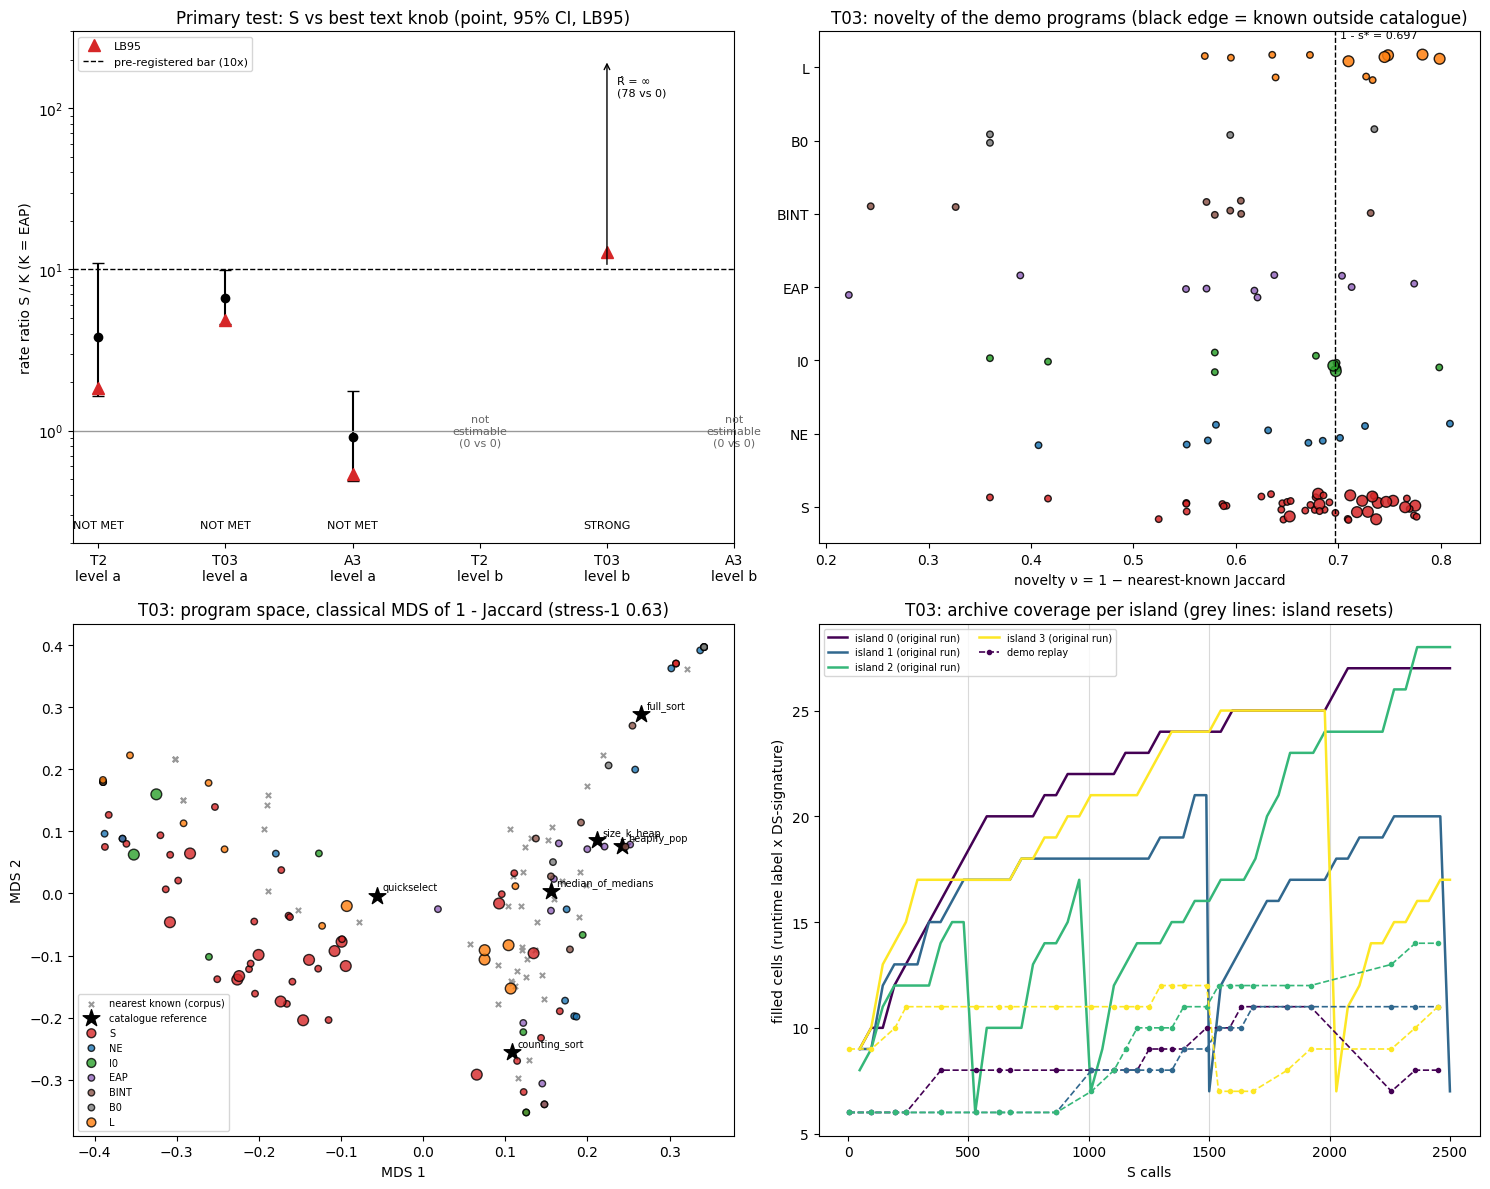

In [30]:
def classical_mds(D: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1][:k]
    X = V[:, idx] * np.sqrt(np.maximum(w[idx], 0))
    Dh = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
    stress = float(np.sqrt(((D - Dh) ** 2).sum() / max((D ** 2).sum(), 1e-12)))
    return X, stress



ARM_COLOR = {"S": "#d62728", "NE": "#1f77b4", "I0": "#2ca02c", "EAP": "#9467bd", "BINT": "#8c564b", "B0": "#7f7f7f",
             "L": "#ff7f0e"}
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# (1) verdict: R_hat with 95% CI, LB95 marked; the pre-registered bar is 10x
ax = axes[0, 0]
items = [(lv, t, res_tests["levels"][lv]["per_task"][t]) for lv in ("a", "b") for t in TASKS]
for i, (lv, t, x) in enumerate(items):
    if not x["estimable"]:
        ax.text(i, 1.0, "not\nestimable\n(0 vs 0)", ha="center", va="center", fontsize=8, color="0.4")
        continue
    lo, hi = x["CI95"]
    if math.isfinite(x["R_hat"]):
        ax.errorbar(i, x["R_hat"], yerr=[[x["R_hat"] - lo], [hi - x["R_hat"]]], fmt="o", color="k", capsize=4)
    else:
        ax.annotate("", xy=(i, 200), xytext=(i, lo), arrowprops=dict(arrowstyle="->", color="k"))
        ax.text(i + 0.08, 120, f"R̂ = ∞\n({x['X_S']} vs {x['X_K']})", fontsize=8)
    ax.plot(i, x["LB95"], marker="^", color="#d62728", ms=9, ls="none", label="LB95" if i == 0 else None)
    ax.text(i, 0.25, x["verdict"], ha="center", fontsize=8, rotation=0)
ax.axhline(10, ls="--", color="k", lw=1, label="pre-registered bar (10x)")
ax.axhline(1, color="0.6", lw=1)
ax.set_yscale("log")
ax.set_ylim(0.2, 300)
ax.set_xticks(range(len(items)), [f"{t}\nlevel {lv}" for lv, t, _ in items])
ax.set_ylabel("rate ratio S / K (K = EAP)")
ax.set_title("Primary test: S vs best text knob (point, 95% CI, LB95)")
ax.legend(loc="upper left", fontsize=8)

# (2) novelty per arm, demo programs, with the variant band
ax = axes[0, 1]
arm_order = [a for a in ARMS + ("L",) if any(r["arm"] == a for r in rows)]
rng_j = np.random.default_rng(0)
for j, a in enumerate(arm_order):
    rs = [r for r in rows if r["arm"] == a and r["novelty"] is not None]
    xs = [r["novelty"] for r in rs]
    ys = j + rng_j.uniform(-0.18, 0.18, len(rs))
    ko = [rec[r["id"]]["metadata_final_class"] == "KNOWN OUTSIDE CATALOGUE" for r in rs]
    ax.scatter(xs, ys, s=[60 if k else 22 for k in ko], color=ARM_COLOR[a], edgecolor=["k" if k else "none" for k in ko],
               alpha=0.85)
ax.axvline(1 - c1_demo["s_star"][DEMO_TASK]["s_star"], ls="--", color="k", lw=1)
ax.text(1 - c1_demo["s_star"][DEMO_TASK]["s_star"] + 0.005, len(arm_order) - 0.6,
        f"1 - s* = {1 - c1_demo['s_star'][DEMO_TASK]['s_star']:.3f}", fontsize=8)
ax.set_yticks(range(len(arm_order)), arm_order)
ax.set_xlabel("novelty ν = 1 − nearest-known Jaccard")
ax.set_title(f"{DEMO_TASK}: novelty of the demo programs (black edge = known outside catalogue)")

# (3) program space: classical MDS of 1 - Jaccard (figure F6 recipe)
ax = axes[1, 0]
progs = [r for r in rows if r.get("correct")]
near_idx = sorted({r["nearest_known_idx"] for r in progs if r.get("nearest_known_idx") is not None
                   and critic.meta[r["nearest_known_idx"]]["kind"] == "corpus"})[:120]
codes_m = [r["code"] for r in progs] + list(obj["references"].values()) + [critic.code(i) for i in near_idx]
kinds = [r["arm"] for r in progs] + ["catalogue"] * len(obj["references"]) + ["known"] * len(near_idx)
M_ = to_matrix([shingle_ids(c) for c in codes_m])
inter_ = (M_ @ M_.T).toarray()
sz_ = np.diag(inter_)
den_ = sz_[:, None] + sz_[None, :] - inter_
Jm = np.where(den_ > 0, inter_ / np.maximum(den_, 1e-9), 1.0)
X_mds, stress1 = classical_mds(1 - Jm)
for kind in ("known", "catalogue") + tuple(arm_order):
    ii = [i for i, k in enumerate(kinds) if k == kind]
    if not ii:
        continue
    if kind == "known":
        ax.scatter(X_mds[ii, 0], X_mds[ii, 1], s=14, marker="x", color="0.6", label="nearest known (corpus)")
    elif kind == "catalogue":
        ax.scatter(X_mds[ii, 0], X_mds[ii, 1], s=160, marker="*", color="k", label="catalogue reference")
        for i in ii:
            ax.annotate(obj["ref_mode"][list(obj["references"])[i - len(progs)]], (X_mds[i, 0], X_mds[i, 1]),
                        fontsize=7, xytext=(4, 4), textcoords="offset points")
    else:
        ko = [rec[progs[i]["id"]]["metadata_final_class"] == "KNOWN OUTSIDE CATALOGUE" for i in ii]
        ax.scatter(X_mds[ii, 0], X_mds[ii, 1], s=[60 if k else 22 for k in ko], color=ARM_COLOR[kind],
                   edgecolor=["k" if k else "none" for k in ko], alpha=0.8, label=kind)
ax.set_title(f"{DEMO_TASK}: program space, classical MDS of 1 - Jaccard (stress-1 {stress1:.2f})")
ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.legend(fontsize=7, loc="best")

# (4) MAP-Elites coverage per island against S calls: original run (solid) and the demo replay (dashed)
ax = axes[1, 1]
dyn = REC["dynamics_T03"]
cov = np.array(dyn["coverage"])
for isl in range(cov.shape[1]):
    ax.plot(dyn["t"], cov[:, isl], color=plt.cm.viridis(isl / 3), lw=1.8, label=f"island {isl} (original run)")
if db.history:
    ht = [h["t"] for h in db.history]
    hc = np.array([h["n_cells"] for h in db.history])
    for isl in range(hc.shape[1]):
        ax.plot(ht, hc[:, isl], color=plt.cm.viridis(isl / 3), lw=1.2, ls="--", marker=".",
                label="demo replay" if isl == 0 else None)
for x in db.resets:
    ax.axvline(x["at_call"], color="0.85", lw=0.8, zorder=0)
ax.set_xlabel("S calls")
ax.set_ylabel("filled cells (runtime label x DS-signature)")
ax.set_title(f"{DEMO_TASK}: archive coverage per island (grey lines: island resets)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

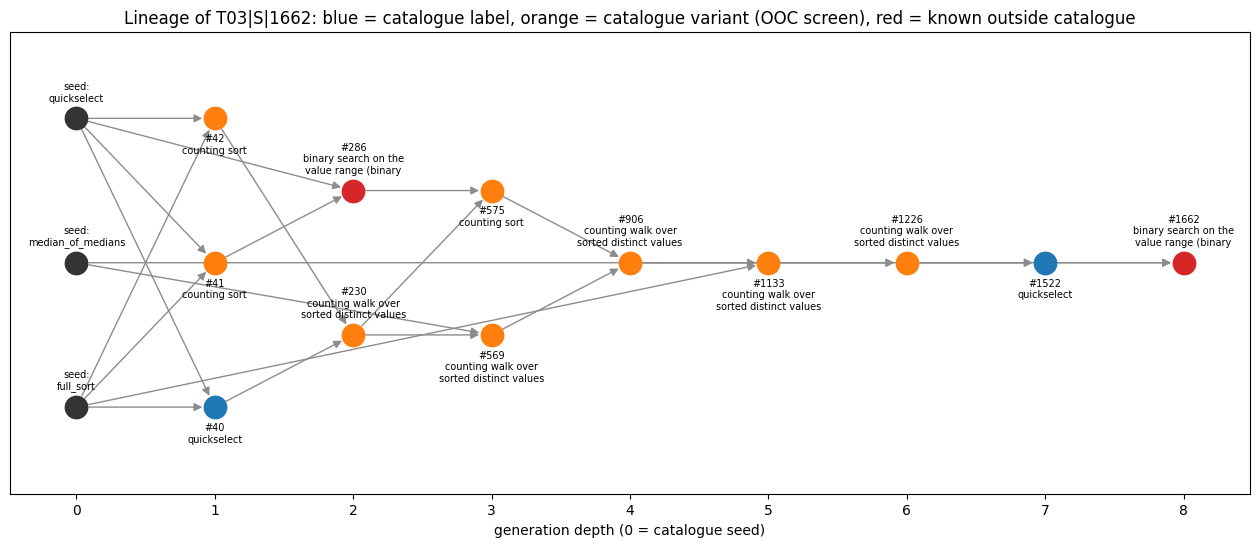

In [31]:
# Lineage tree of the depth-8 known-outside-catalogue program (x = depth, edges = parent -> child)
lin_set = set(lin_ids)
nodes = {}
for i in lin_ids:
    for p in rec[i]["metadata_parent_ids"]:
        if p.startswith("seed:"):
            nodes[p] = 0
    nodes[i] = rec[i]["metadata_depth"]
by_depth = defaultdict(list)
for n, d in sorted(nodes.items(), key=lambda kv: (kv[1], kv[0])):
    by_depth[d].append(n)
pos = {n: (d, k - (len(ns) - 1) / 2) for d, ns in by_depth.items() for k, n in enumerate(ns)}
fig, ax = plt.subplots(figsize=(16, 6))
for i in lin_ids:
    for p in rec[i]["metadata_parent_ids"]:
        if p in pos:
            ax.annotate("", xy=pos[i], xytext=pos[p], arrowprops=dict(arrowstyle="-|>", color="0.55", lw=1,
                                                                      shrinkA=9, shrinkB=9, mutation_scale=12))
for n, (x, y) in pos.items():
    if n.startswith("seed:"):
        col, txt = "0.2", "seed:\n" + n.split(":")[-1]
    else:
        fc = rec[n]["metadata_final_class"]
        col = {"KNOWN OUTSIDE CATALOGUE": "#d62728", "CATALOGUE VARIANT": "#ff7f0e"}.get(fc, "#1f77b4")
        name = rec[n]["metadata_named_algorithm"] or rec[n]["metadata_label"]
        txt = f"#{n.split('|')[-1]}\n" + "\n".join(textwrap.wrap(name, 22)[:2])
    ax.scatter([x], [y], s=260, color=col, zorder=3)
    up = x % 2 == 0                     # alternate label side by depth so neighbours do not collide
    ax.annotate(txt, (x, y), fontsize=7, xytext=(0, 11 if up else -11), textcoords="offset points", ha="center",
                va="bottom" if up else "top")
ax.set_xlabel("generation depth (0 = catalogue seed)")
ax.set_yticks([])
ax.set_title(f"Lineage of {lin['target']}: blue = catalogue label, orange = catalogue variant (OOC screen), "
             f"red = known outside catalogue")
ax.margins(x=0.06, y=0.3)
plt.show()

## What the demo shows

* **The CPU half of the pipeline reproduces.**
  * The evaluator re-certifies every replayed program.
  * The critic recovers the recorded nearest-known similarities exactly from the corpus subset.
  * Commit #1 recomputes the variant bands s\*.
  * The round-0 parent draws match the original run.
* **The verdict follows from the counts.** S's advantage over the best prompting knob is real but far below 10× at
  level a (T03: 6.65×, LB95 4.86). It is large only at level b on T03, where the knobs produced no
  known-outside-catalogue program at all.
* **No new algorithm.** What the search finds outside the catalogue on T03 are known techniques: binary search over the
  value range, Fenwick-tree or treap order statistics, and bucket select. The search reaches them by composing parents
  across generations (see the lineage), not by inventing a new mechanism.

**Scaling up.**

* Set `N_EVAL_PROGRAMS = 100` to replay every demo program.
* Set `PLACEBO_REPS = 200` and `BOOTSTRAP_REPS = 2000` to match the original analysis.
* Regenerating the programs themselves needs the original repository's GPU stages (`method.py --stage calib`, then
  `--stage run`, with about 20 GB of VRAM) and an OpenRouter key for the judges and arm L.